# Synthetic data for industrial fire detection

Binary fire / no-fire image classification with transfer learning (MobileNetV2 and DenseNet121, ImageNet weights, frozen backbone).
Models are trained on five mixes of synthetic and real images (100% real, 100% synthetic, 80/20, 50/50, 20/80 synthetic/real) and **always evaluated on the real test set**.

Set `DATA_ROOT` below (or the `FIRE_DATA_ROOT` environment variable) to your local data folder. See the repository README for dataset sources and layout.

In [40]:
%pip install tensorflow

Note: you may need to restart the kernel to use updated packages.


### 100 % Real 

In [48]:
import os
import tensorflow as tf
import matplotlib.pyplot as plt

tf.compat.v1.enable_eager_execution()

In [ ]:
import os

# Folder that holds the datasets, laid out as:
#   real/train/{images,labels}   real/test/{images,labels}
#   synthetic/{train,valid,test}/ (+ Labels.txt in each)
# Override with:  export FIRE_DATA_ROOT=/path/to/data
DATA_ROOT = os.environ.get("FIRE_DATA_ROOT", "data")

In [5]:
real_train_img=f"{DATA_ROOT}/real/train/images"
real_train_lab=f"{DATA_ROOT}/real/train/labels"
real_test_img=f"{DATA_ROOT}/real/test/images"
real_test_lab=f"{DATA_ROOT}/real/test/labels"

In [9]:
def load_image_and_label(image_path):
    img = tf.io.read_file(image_path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, [224, 224])
    img = img / 255.0

    # Convert .jpg path → .txt path
    label_path = tf.strings.regex_replace(image_path, "images", "labels")
    label_path = tf.strings.regex_replace(label_path, ".jpg", ".txt")

    # Read .txt content and assign label
    label_content = tf.io.read_file(label_path)
    label = tf.cond(tf.strings.length(label_content) > 0,
                    lambda: tf.constant(1, dtype=tf.int32),
                    lambda: tf.constant(0, dtype=tf.int32))
    
    return img, label


In [10]:
def build_dataset(image_dir, batch_size=32, shuffle=True):
    image_files = [os.path.join(image_dir, f)
                   for f in os.listdir(image_dir)
                   if f.endswith(".jpg")]

    dataset = tf.data.Dataset.from_tensor_slices(image_files)
    dataset = dataset.map(load_image_and_label, num_parallel_calls=tf.data.AUTOTUNE)

    if shuffle:
        dataset = dataset.shuffle(buffer_size=500)

    return dataset.batch(batch_size).prefetch(tf.data.AUTOTUNE)


In [11]:
train_ds = build_dataset(real_train_img)
test_ds_1 = build_dataset(real_test_img, shuffle=False)


In [19]:
for images, labels in train_ds.take(1):
    print(images.shape, labels.numpy())


(32, 224, 224, 3) [0 1 0 1 1 0 0 1 1 0 1 1 1 1 1 1 0 1 1 1 1 1 0 0 0 0 0 0 0 0 1 1]


2025-08-29 13:35:08.774558: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


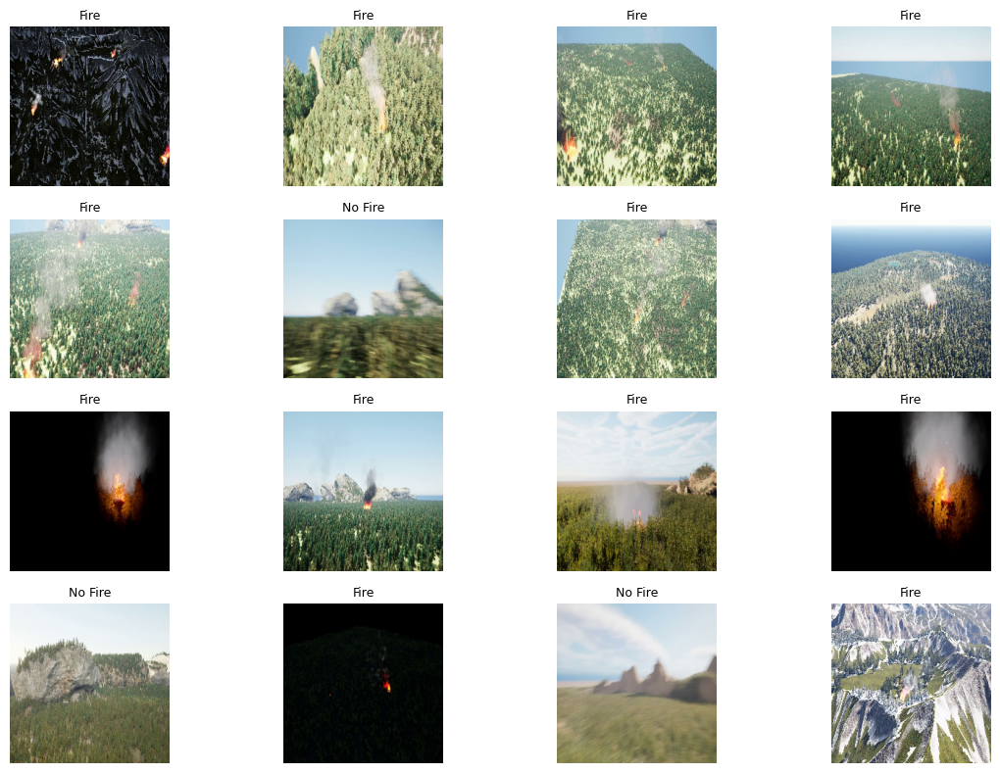

In [98]:
# ==== Preview some REAL training images ====
import matplotlib.pyplot as plt

for images, labels in train_ds.take(1):   # take 1 batch from training set
    images = images.numpy()
    labels = labels.numpy()

    plt.figure(figsize=(12, 8))
    for i in range(min(16, images.shape[0])):  # show up to 16 images
        ax = plt.subplot(4, 4, i + 1)
        plt.imshow(images[i])
        label_text = "Fire" if labels[i] == 1 else "No Fire"
        plt.title(label_text, fontsize=9)
        plt.axis("off")
    plt.tight_layout()
    plt.show()


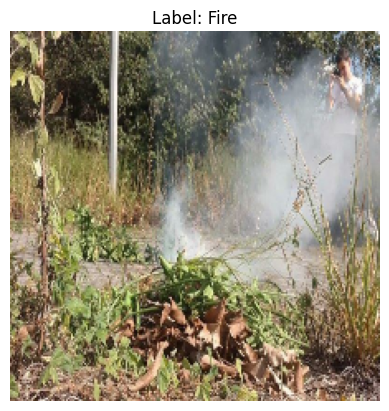

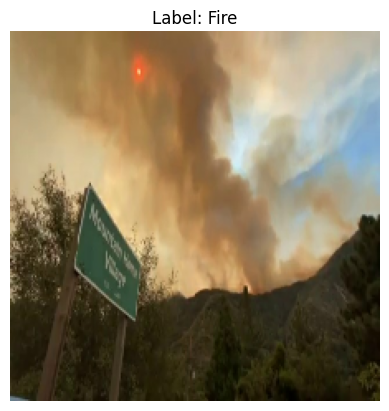

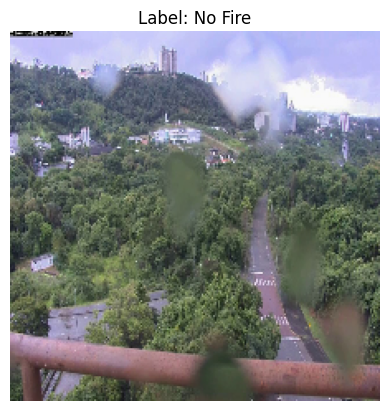

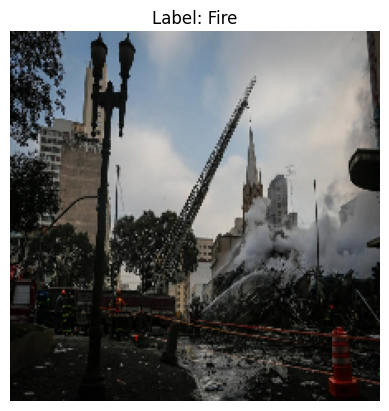

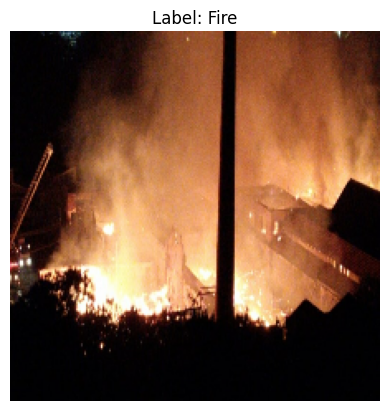

In [120]:
class_names = ['No Fire', 'Fire']

for images, labels in train_ds.take(1):
    for i in range(5):
        plt.imshow(images[i].numpy())
        plt.title(f"Label: {class_names[labels[i].numpy()]}")
        plt.axis("off")
        plt.show()


In [12]:
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt


In [13]:
base_model = MobileNetV2(input_shape=(224, 224, 3),
                         include_top=False,
                         weights='imagenet')
base_model.trainable = False  # freeze pre-trained layers

model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(1, activation='sigmoid')  # binary classification
])

model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

model.summary()

model.save("mobilenetv2_fire.h5")



Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:

# Callbacks
early_stop = EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True, verbose=1)
checkpoint = ModelCheckpoint("mobilenetv2_20synthetic_best.h5", monitor="val_loss", save_best_only=True, verbose=1)


In [11]:
EPOCHS = 8

# model = load_model("mobilenetv2_fire.h5")
# Recompile with run_eagerly (either one is enough)
# model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"], run_eagerly=True)


history_real = model.fit(
    train_ds,
    validation_data=test_ds_1,
    epochs=EPOCHS
)

# model.save("mobilenetv2_fire.h5")

with open("history_real.json",'w') as f:
    json.dump(history_real.history,f)


Epoch 1/8
539/539 ━━━━━━━━━━━━━━━━━━━━ 108s 199ms/step - accuracy: 0.7196 - loss: 0.5210 - val_accuracy: 0.8328 - val_loss: 0.3890
Epoch 2/8
539/539 ━━━━━━━━━━━━━━━━━━━━ 813s 2s/step - accuracy: 0.8448 - loss: 0.3539 - val_accuracy: 0.8572 - val_loss: 0.3451
Epoch 3/8
539/539 ━━━━━━━━━━━━━━━━━━━━ 113s 209ms/step - accuracy: 0.8631 - loss: 0.3204 - val_accuracy: 0.8679 - val_loss: 0.3239
Epoch 4/8
539/539 ━━━━━━━━━━━━━━━━━━━━ 697s 1s/step - accuracy: 0.8768 - loss: 0.2986 - val_accuracy: 0.8725 - val_loss: 0.3117
Epoch 5/8
539/539 ━━━━━━━━━━━━━━━━━━━━ 114s 210ms/step - accuracy: 0.8835 - loss: 0.2826 - val_accuracy: 0.8741 - val_loss: 0.3084
Epoch 6/8
539/539 ━━━━━━━━━━━━━━━━━━━━ 123s 227ms/step - accuracy: 0.8932 - loss: 0.2711 - val_accuracy: 0.8806 - val_loss: 0.2960
Epoch 7/8
539/539 ━━━━━━━━━━━━━━━━━━━━ 132s 244ms/step - accuracy: 0.8922 - loss: 0.2647 - val_accuracy: 0.8730 - val_loss: 0.3061
Epoch 8/8
539/539 ━━━━━━━━━━━━━━━━━━━━ 140s 259ms/step - accuracy: 0.9007 - loss: 0.2558 

In [19]:
# model.save("mobilenetv2_fire.h5")

with open("history_real.json",'w') as f:
    json.dump(history_real.history,f)

model.save("mobilenetv2_fire_real.h5")


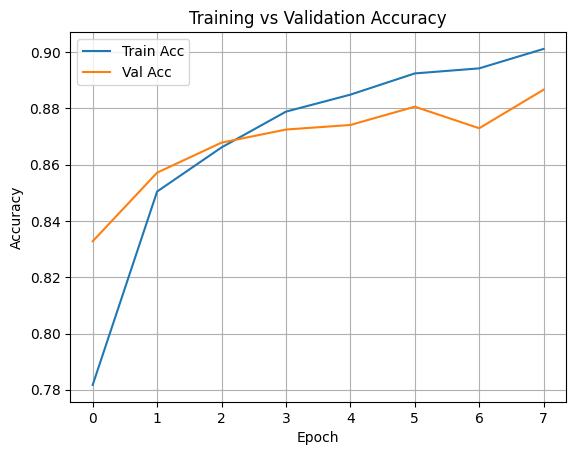

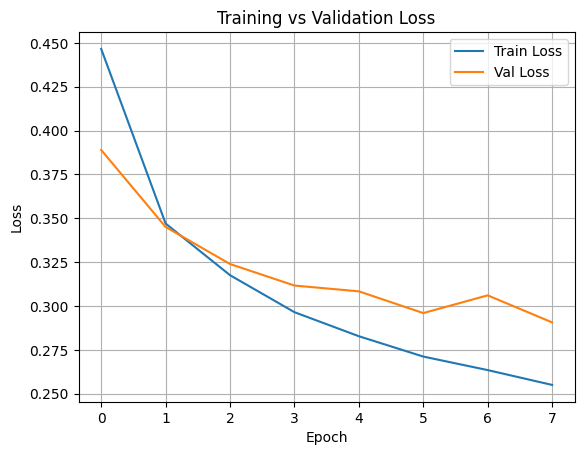

In [14]:
import matplotlib.pyplot as plt
from tensorflow.keras.models import load_model

model = load_model("mobilenetv2_fire_real.h5")
# Recompile with run_eagerly (either one is enough)
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"], run_eagerly=True)


with open("history_real.json", "r") as f:
    hist = json.load(f)


# Accuracy plot
plt.plot(hist['accuracy'], label='Train Acc')
plt.plot(hist['val_accuracy'], label='Val Acc')
plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# Loss plot
plt.plot(hist['loss'], label='Train Loss')
plt.plot(hist['val_loss'], label='Val Loss')
plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()


In [15]:


# model.compile(
#     optimizer='adam',
#     loss='binary_crossentropy',
#     metrics=['accuracy']
# )
model.evaluate(test_ds_1)
predictions = model.predict(test_ds_1)

135/135 ━━━━━━━━━━━━━━━━━━━━ 49s 363ms/step - accuracy: 0.8819 - loss: 0.2996
135/135 ━━━━━━━━━━━━━━━━━━━━ 49s 360ms/step


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 360ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 362ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 354ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 369ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 354ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 354ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 357ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 349ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 355ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 352ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 355ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 351ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 346ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 351ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 354ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 355ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 352ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 357ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 378ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 377ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 357ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 355ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 353ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 352ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 352ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 

2025-09-01 12:52:33.194874: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


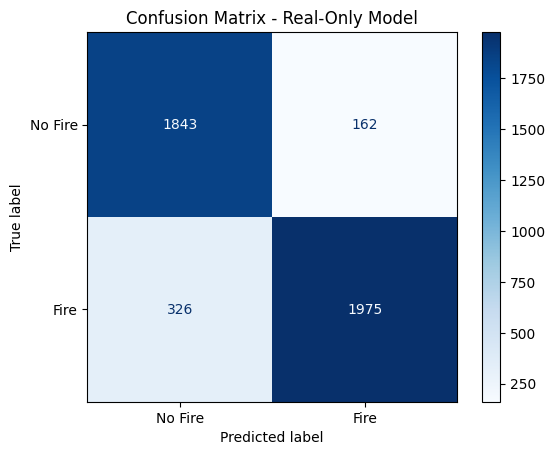

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Load the model (optional if already in memory)
# from tensorflow.keras.models import load_model
# model = load_model('mobilenetv2_real_final.h5')

# Get true and predicted labels from test set
y_true = []
y_pred = []

for images, labels in test_ds_1:
    preds = model.predict(images)
    preds = np.round(preds).astype(int).flatten()
    y_pred.extend(preds)
    y_true.extend(labels.numpy())

# Generate confusion matrix
cm_1 = confusion_matrix(y_true, y_pred)
disp_1 = ConfusionMatrixDisplay(confusion_matrix=cm_1, display_labels=["No Fire", "Fire"])

# Plot
disp_1.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix - Real-Only Model")
plt.show()


In [125]:
from sklearn.metrics import classification_report
print(classification_report(y_true, y_pred, target_names=["No Fire", "Fire"]))


              precision    recall  f1-score   support

     No Fire       0.85      0.92      0.88      2005
        Fire       0.92      0.86      0.89      2301

    accuracy                           0.89      4306
   macro avg       0.89      0.89      0.89      4306
weighted avg       0.89      0.89      0.89      4306



In [69]:
report_real = classification_report(y_true, y_pred, target_names=["No Fire", "Fire"],output_dict=True)

print(report_real)

# Extract metrics for the 'Fire' class
precision_real = report_real['Fire']['precision']
recall_real = report_real['Fire']['recall']
f1_real = report_real['Fire']['f1-score']
accuracy_real = report_real['accuracy']

{'No Fire': {'precision': 0.8497003227293684, 'recall': 0.9192019950124688, 'f1-score': 0.8830857690464782, 'support': 2005.0}, 'Fire': {'precision': 0.9241927936359382, 'recall': 0.85832246849196, 'f1-score': 0.8900405588102749, 'support': 2301.0}, 'accuracy': 0.8866697631212263, 'macro avg': {'precision': 0.8869465581826532, 'recall': 0.8887622317522144, 'f1-score': 0.8865631639283765, 'support': 4306.0}, 'weighted avg': {'precision': 0.889506912500854, 'recall': 0.8866697631212263, 'f1-score': 0.8868022045426455, 'support': 4306.0}}


### 100 % Sythetic 

In [22]:
def parse_label_file(label_file_path):
    """
    Parses a label file where each line contains:
    image_name [x1,y1,x2,y2,class_id] ...
    Returns a dictionary mapping image_name to binary label (1 if fire is present, 0 otherwise).
    """
    image_labels = {}

    with open(label_file_path, 'r') as f:
        for line in f:
            parts = line.strip().split()

            if not parts:
                continue  # skip empty lines

            image_name = parts[0]
            boxes = parts[1:]

            label = 0  # assume no fire

            for box in boxes:
                try:
                    class_id = int(box.strip().split(',')[-1])
                    if class_id == 0:  # fire
                        label = 1
                        break  # no need to check further
                except Exception as e:
                    print(f"Warning: failed to parse box '{box}' in image '{image_name}': {e}")

            image_labels[image_name] = label

    return image_labels


In [23]:
train_labels = parse_label_file(f"{DATA_ROOT}/synthetic/train/Labels.txt")
val_labels   = parse_label_file(f"{DATA_ROOT}/synthetic/valid/Labels.txt")
test_labels  = parse_label_file(f"{DATA_ROOT}/synthetic/test/Labels.txt")




In [24]:
# import tensorflow as tf
# import os

def get_dataset(image_dir, label_dict, batch_size=32, shuffle=True):
    image_paths = []
    labels = []

    for fname in os.listdir(image_dir):
        if fname.endswith(".jpg") and fname in label_dict:
            image_paths.append(os.path.join(image_dir, fname))
            labels.append(label_dict[fname])

    ds = tf.data.Dataset.from_tensor_slices((image_paths, labels))

    def load_fn(image_path, label):
        img = tf.io.read_file(image_path)
        img = tf.image.decode_jpeg(img, channels=3)
        img = tf.image.resize(img, [224, 224])
        img = img / 255.0
        label = tf.cast(label, tf.int32)
        return img, label

    ds = ds.map(load_fn, num_parallel_calls=tf.data.AUTOTUNE)

    if shuffle:
        ds = ds.shuffle(1000)

    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)


In [25]:
train_ds = get_dataset(f"{DATA_ROOT}/synthetic/train", train_labels)
val_ds   = get_dataset(f"{DATA_ROOT}/synthetic/valid", val_labels, shuffle=False)
test_ds_2  = get_dataset(f"{DATA_ROOT}/synthetic/test", test_labels, shuffle=False)


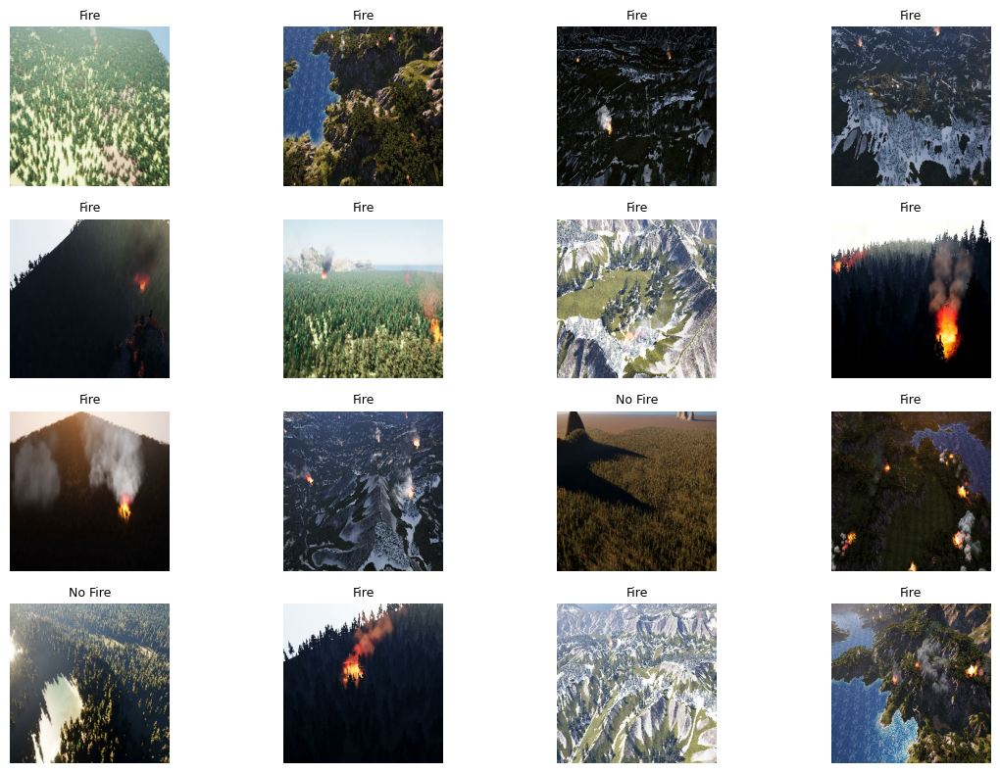

In [97]:
# ==== Preview some synthetic training images ====
import matplotlib.pyplot as plt

for images, labels in train_ds.take(1):
    images = images.numpy()
    labels = labels.numpy()

    plt.figure(figsize=(12, 8))
    for i in range(min(16, images.shape[0])):  # Show up to 16 images
        ax = plt.subplot(4, 4, i + 1)
        plt.imshow(images[i])
        label_text = "Fire" if labels[i] == 1 else "No Fire"
        plt.title(label_text, fontsize=9)
        plt.axis("off")
    plt.tight_layout()
    plt.show()


In [74]:
model = load_model("mobilenetv2_fire.h5")
# Recompile with run_eagerly (either one is enough)
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"], run_eagerly=True)


In [29]:

from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint


# Define early stopping
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=2,               # Stop after 2 epochs of no improvement
    restore_best_weights=True,
    verbose=1
)

# Optional: save best model
checkpoint = ModelCheckpoint(
    "mobilenetv2_synthetic_best.h5",
    monitor="loss",
    save_best_only=True,
    verbose=1
)

# Train with callbacks
history = model.fit(
    train_ds,
    validation_data=test_ds_2,
    epochs=20,
    callbacks=[early_stop, checkpoint]
)

model.save("mobilenetv2_fire_syn.h5")


with open("history_syn.json",'w') as f:
    json.dump(history.history,f)



Epoch 1/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8864 - loss: 0.2987
Epoch 1: loss improved from inf to 0.25502, saving model to mobilenetv2_synthetic_best.h5


88/88 ━━━━━━━━━━━━━━━━━━━━ 99s 1s/step - accuracy: 0.8865 - loss: 0.2982 - val_accuracy: 0.9247 - val_loss: 0.2399
Epoch 2/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9246 - loss: 0.2091
Epoch 2: loss improved from 0.25502 to 0.20345, saving model to mobilenetv2_synthetic_best.h5


88/88 ━━━━━━━━━━━━━━━━━━━━ 100s 1s/step - accuracy: 0.9245 - loss: 0.2090 - val_accuracy: 0.9377 - val_loss: 0.2162
Epoch 3/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9279 - loss: 0.2005
Epoch 3: loss improved from 0.20345 to 0.17947, saving model to mobilenetv2_synthetic_best.h5


88/88 ━━━━━━━━━━━━━━━━━━━━ 102s 1s/step - accuracy: 0.9280 - loss: 0.2003 - val_accuracy: 0.9481 - val_loss: 0.2037
Epoch 4/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9426 - loss: 0.1616
Epoch 4: loss improved from 0.17947 to 0.16464, saving model to mobilenetv2_synthetic_best.h5


88/88 ━━━━━━━━━━━━━━━━━━━━ 100s 1s/step - accuracy: 0.9426 - loss: 0.1617 - val_accuracy: 0.9481 - val_loss: 0.1956
Epoch 5/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9462 - loss: 0.1506
Epoch 5: loss improved from 0.16464 to 0.15343, saving model to mobilenetv2_synthetic_best.h5


...

88/88 ━━━━━━━━━━━━━━━━━━━━ 101s 1s/step - accuracy: 0.9525 - loss: 0.1398 - val_accuracy: 0.9506 - val_loss: 0.1680
Epoch 8/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9599 - loss: 0.1273
Epoch 8: loss improved from 0.13745 to 0.12826, saving model to mobilenetv2_synthetic_best.h5


88/88 ━━━━━━━━━━━━━━━━━━━━ 96s 1s/step - accuracy: 0.9598 - loss: 0.1273 - val_accuracy: 0.9506 - val_loss: 0.1695
Epoch 9/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 996ms/step - accuracy: 0.9523 - loss: 0.1297
Epoch 9: loss improved from 0.12826 to 0.12277, saving model to mobilenetv2_synthetic_best.h5


88/88 ━━━━━━━━━━━━━━━━━━━━ 93s 1s/step - accuracy: 0.9523 - loss: 0.1296 - val_accuracy: 0.9532 - val_loss: 0.1640
Epoch 10/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 948ms/step - accuracy: 0.9627 - loss: 0.1169
Epoch 10: loss improved from 0.12277 to 0.12053, saving model to mobilenetv2_synthetic_best.h5


88/88 ━━━━━━━━━━━━━━━━━━━━ 89s 1s/step - accuracy: 0.9627 - loss: 0.1169 - val_accuracy: 0.9506 - val_loss: 0.1768
Epoch 11/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 899ms/step - accuracy: 0.9569 - loss: 0.1152
Epoch 11: loss improved from 0.12053 to 0.11275, saving model to mobilenetv2_synthetic_best.h5


88/88 ━━━━━━━━━━━━━━━━━━━━ 85s 955ms/step - accuracy: 0.9570 - loss: 0.1152 - val_accuracy: 0.9377 - val_loss: 0.1940
Epoch 11: early stopping
Restoring model weights from the end of the best epoch: 9.


In [75]:
import numpy as np

with open("history_syn.json", "r") as f:
    hist_syn = json.load(f)


# Get validation loss history
val_losses = hist_syn['val_loss']

# Find the epoch with the minimum validation loss
best_epoch = np.argmin(val_losses) + 1  # add 1 for human-readable (1-indexed)
best_val_loss = val_losses[best_epoch - 1]

print(f"Best epoch: {best_epoch}")
print(f"Validation loss at best epoch: {best_val_loss:.4f}")


Best epoch: 9
Validation loss at best epoch: 0.1640


In [76]:
model = load_model("mobilenetv2_fire_syn.h5")
test_loss, test_accuracy = model.evaluate(test_ds_2)
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Loss: {test_loss:.4f}")


13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 146ms/step - accuracy: 0.9575 - loss: 0.1380
Test Accuracy: 0.9532
Test Loss: 0.1640


135/135 ━━━━━━━━━━━━━━━━━━━━ 22s 163ms/step - accuracy: 0.8536 - loss: 0.3478

📊 Test Accuracy on Real Data: 0.8576
📉 Test Loss on Real Data: 0.3388
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 411ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 166ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 181ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 179ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 175ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 165ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 182ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 179ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 177ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 195ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 192ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 176ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 182ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 179ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 176ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 178ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 191ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 169ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 177ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 161ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 170ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 167m

2025-09-03 19:34:38.473414: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


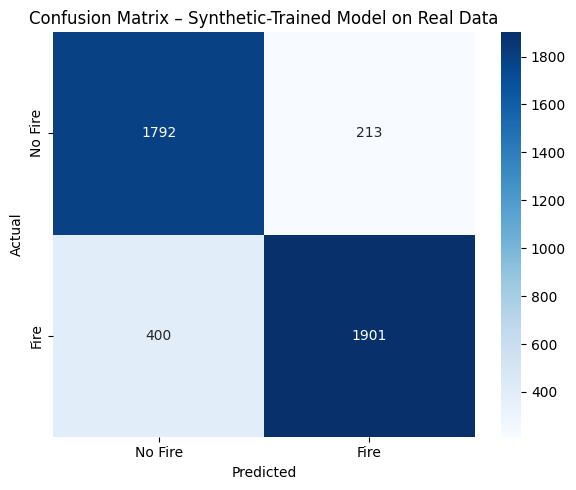

Classification Report:
              precision    recall  f1-score   support

     No Fire       0.82      0.89      0.85      2005
        Fire       0.90      0.83      0.86      2301

    accuracy                           0.86      4306
   macro avg       0.86      0.86      0.86      4306
weighted avg       0.86      0.86      0.86      4306



In [49]:
### === Evaluate Synthetic-Trained Model on Real Test Set === ###

# Reuse this if already defined earlier in your real-only notebook
def load_image_and_label(image_path):
    img = tf.io.read_file(image_path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, [224, 224])
    img = img / 255.0

    label_path = tf.strings.regex_replace(image_path, "images", "labels")
    label_path = tf.strings.regex_replace(label_path, ".jpg", ".txt")

    label_content = tf.io.read_file(label_path)
    label = tf.cond(tf.strings.length(label_content) > 0,
                    lambda: tf.constant(1, dtype=tf.int32),
                    lambda: tf.constant(0, dtype=tf.int32))
    
    return img, label

def build_dataset(image_dir, batch_size=32, shuffle=False):
    image_files = [os.path.join(image_dir, f) for f in os.listdir(image_dir) if f.endswith(".jpg")]
    dataset = tf.data.Dataset.from_tensor_slices(image_files)
    dataset = dataset.map(load_image_and_label, num_parallel_calls=tf.data.AUTOTUNE)
    if shuffle:
        dataset = dataset.shuffle(buffer_size=500)
    return dataset.batch(batch_size).prefetch(tf.data.AUTOTUNE)

# 👇 Set this path to your actual real test image folder
real_test_img = f"{DATA_ROOT}/real/test/images"
real_test_ds = build_dataset(real_test_img)

# ✅ Evaluate on real data
test_loss_real, test_accuracy_real = model.evaluate(real_test_ds)
print(f"\n📊 Test Accuracy on Real Data: {test_accuracy_real:.4f}")
print(f"📉 Test Loss on Real Data: {test_loss_real:.4f}")

# Generate confusion matrix + classification report
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

y_true_2 = []
y_pred_2 = []

for images, labels in real_test_ds:
    preds = model.predict(images)
    preds = (preds > 0.5).astype(int)
    y_pred_2.extend(preds.flatten())
    y_true_2.extend(labels.numpy().flatten())

cm_2 = confusion_matrix(y_true_2, y_pred_2)
labels_names = ["No Fire", "Fire"]

plt.figure(figsize=(6, 5))
sns.heatmap(cm_2, annot=True, fmt="d", cmap="Blues", xticklabels=labels_names, yticklabels=labels_names)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix – Synthetic-Trained Model on Real Data")
plt.tight_layout()
plt.show()

print("Classification Report:")
print(classification_report(y_true_2, y_pred_2, target_names=labels_names))

report_syn= classification_report(y_true_2, y_pred_2, target_names=labels_names,output_dict=True)


# Extract metrics for the 'Fire' class
precision_syn = report_syn['Fire']['precision']
recall_syn = report_syn['Fire']['recall']
f1_syn = report_syn['Fire']['f1-score']
accuracy_syn = report_syn['accuracy']

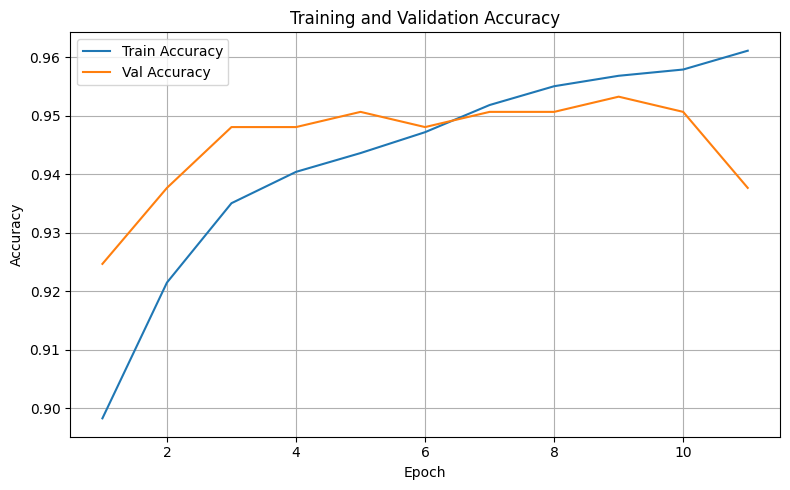

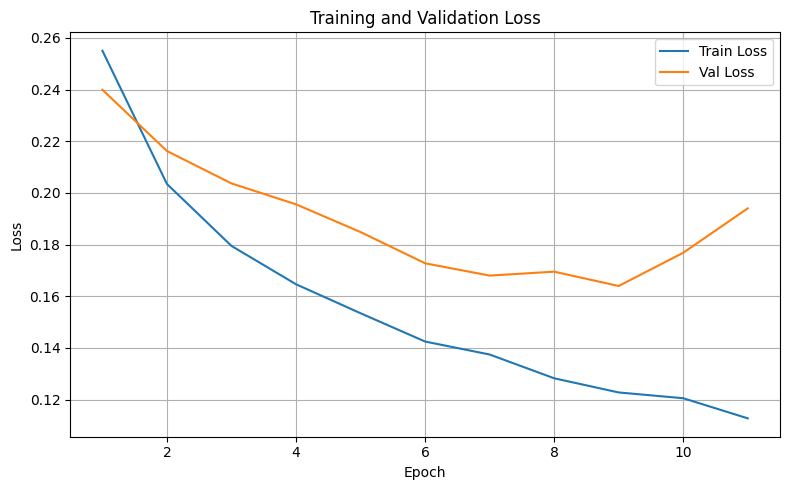

In [135]:

import matplotlib.pyplot as plt

# Extract from history
acc = hist_syn['accuracy']
val_acc = hist_syn['val_accuracy']
loss = hist_syn['loss']
val_loss = hist_syn['val_loss']
epochs_range = range(1, len(acc) + 1)  # Dynamic to EarlyStopping cutoff

# Accuracy plot
plt.figure(figsize=(8, 5))
plt.plot(epochs_range, acc, label='Train Accuracy')
plt.plot(epochs_range, val_acc, label='Val Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Loss plot
plt.figure(figsize=(8, 5))
plt.plot(epochs_range, loss, label='Train Loss')
plt.plot(epochs_range, val_loss, label='Val Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# 80-20(synthetic-real)split 

In [68]:
import os

def parse_yolo_labels(label_folder):
    """
    Parses YOLO .txt files into binary labels:
    0 = no fire (empty file or only class 1), 1 = fire (if any class 0 box).
    """
    label_dict = {}
    for file in os.listdir(label_folder):
        if file.endswith(".txt"):
            filepath = os.path.join(label_folder, file)
            with open(filepath, 'r') as f:
                lines = f.readlines()
                image_name = file.replace(".txt", ".jpg")
                label = 0  # default: no fire
                for line in lines:
                    if line.strip().startswith("0"):
                        label = 1
                        break
                label_dict[image_name] = label
    return label_dict


def parse_label_file(label_file_path):
    image_labels = {}
    with open(label_file_path, 'r') as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) == 0:
                continue
            image_name = parts[0]
            label = 0
            for box in parts[1:]:
                class_id = int(box.split(',')[-1])
                if class_id == 0:
                    label = 1
                    break
            image_labels[image_name] = label
    return image_labels


In [69]:
# Real paths
REAL_TRAIN_IMG_DIR = f"{DATA_ROOT}/real/train/images"
REAL_TRAIN_LABEL_DIR = f"{DATA_ROOT}/real/train/labels"

# Synthetic paths
SYN_TRAIN_IMG_DIR = f"{DATA_ROOT}/synthetic/train"
SYN_LABEL_FILE = f"{DATA_ROOT}/synthetic/train/Labels.txt"

# Parse label files
real_labels = parse_yolo_labels(REAL_TRAIN_LABEL_DIR)
train_labels = parse_label_file(SYN_LABEL_FILE)


In [70]:
def get_dataset(image_dir, label_dict, shuffle=True):
    image_paths = []
    labels = []

    for fname in os.listdir(image_dir):
        if fname.endswith(".jpg") and fname in label_dict:
            image_paths.append(os.path.join(image_dir, fname))
            labels.append(label_dict[fname])

    # TensorFlow dataset
    path_ds = tf.data.Dataset.from_tensor_slices(image_paths)
    label_ds = tf.data.Dataset.from_tensor_slices(labels)
    img_ds = path_ds.map(lambda x: process_image(x))  # assumes 224x224 resizer

    full_ds = tf.data.Dataset.zip((img_ds, label_ds))
    if shuffle:
        full_ds = full_ds.shuffle(buffer_size=10000)

    return full_ds


In [71]:
import tensorflow as tf

def process_image(image_path):
    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)  # Ensure RGB
    image = tf.image.resize(image, [224, 224])
    image = image / 255.0  # Normalize to [0, 1]
    return image


In [72]:
real_train_ds = get_dataset(REAL_TRAIN_IMG_DIR, real_labels, shuffle=True)
synthetic_train_ds = get_dataset(SYN_TRAIN_IMG_DIR, train_labels, shuffle=True)


In [174]:
BATCH_SIZE = 32

# Take 20% of real training dataset
#real_cardinality = tf.data.experimental.cardinality(real_train_ds).numpy()
#real_20_ds = real_train_ds.take(int(0.2 * real_cardinality))

# Combine
#mixed_train_ds = synthetic_train_ds.concatenate(real_20_ds)

# Shuffle + batch
#mixed_train_ds = mixed_train_ds.shuffle(10000).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

import tensorflow as tf

BATCH_SIZE = 32

# Step 1: Count number of examples
real_count = tf.data.experimental.cardinality(real_train_ds).numpy()
synthetic_count = tf.data.experimental.cardinality(synthetic_train_ds).numpy()
total_needed = real_count + synthetic_count

# Step 2: Compute 80/20 counts from total
target_total = int(0.8 * total_needed)  # 80% synthetic
target_real = total_needed - target_total  # 20% real

# Step 3: Take desired counts
synthetic_trimmed = synthetic_train_ds.take(target_total)
real_trimmed = real_train_ds.take(target_real)

# Step 4: Combine
mixed_train_ds_80_20 = synthetic_trimmed.concatenate(real_trimmed)

# Step 5: Shuffle, batch, prefetch
mixed_train_ds_80_20 = mixed_train_ds_80_20.shuffle(10000).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)




In [41]:
print(tf.executing_eagerly())  

True


In [47]:
model = load_model("mobilenetv2_fire.h5")
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

history_80_20= model.fit(
    mixed_train_ds_80_20,
    validation_data=val_ds,  # your existing synthetic val
    epochs=20,
    callbacks=[early_stop, checkpoint]
)


with open("history_80_20.json",'w') as f:
    json.dump(history_80_20.history,f)

Epoch 1/20
213/213 ━━━━━━━━━━━━━━━━━━━━ 0s 144ms/step - accuracy: 0.8618 - loss: 0.3764
Epoch 1: loss did not improve from 0.11275
213/213 ━━━━━━━━━━━━━━━━━━━━ 46s 166ms/step - accuracy: 0.8618 - loss: 0.3761 - val_accuracy: 0.9025 - val_loss: 0.2406
Epoch 2/20


2025-08-14 11:10:22.220948: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:452] ShuffleDatasetV3:3562: Filling up shuffle buffer (this may take a while): 5715 of 10000


  1/213 ━━━━━━━━━━━━━━━━━━━━ 39:13 11s/step - accuracy: 0.8438 - loss: 0.2972

2025-08-14 11:10:23.168864: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:482] Shuffle buffer filled.


213/213 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step - accuracy: 0.8844 - loss: 0.3167
Epoch 2: loss did not improve from 0.11275
213/213 ━━━━━━━━━━━━━━━━━━━━ 47s 167ms/step - accuracy: 0.8844 - loss: 0.3167 - val_accuracy: 0.9170 - val_loss: 0.2124
Epoch 3/20


...

213/213 ━━━━━━━━━━━━━━━━━━━━ 0s 185ms/step - accuracy: 0.9003 - loss: 0.2571
Epoch 12: loss did not improve from 0.11275
213/213 ━━━━━━━━━━━━━━━━━━━━ 58s 210ms/step - accuracy: 0.9003 - loss: 0.2571 - val_accuracy: 0.9381 - val_loss: 0.1646
Epoch 13/20


2025-08-14 11:20:22.070419: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:452] ShuffleDatasetV3:3562: Filling up shuffle buffer (this may take a while): 2803 of 10000


  1/213 ━━━━━━━━━━━━━━━━━━━━ 48:54 14s/step - accuracy: 0.9688 - loss: 0.1310

2025-08-14 11:20:25.581249: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:482] Shuffle buffer filled.


213/213 ━━━━━━━━━━━━━━━━━━━━ 0s 185ms/step - accuracy: 0.9052 - loss: 0.2485
Epoch 13: loss did not improve from 0.11275
213/213 ━━━━━━━━━━━━━━━━━━━━ 59s 211ms/step - accuracy: 0.9051 - loss: 0.2485 - val_accuracy: 0.9381 - val_loss: 0.1632
Epoch 13: early stopping
Restoring model weights from the end of the best epoch: 11.


In [48]:
model.save("mobilenetv2_80_20.h5")




In [175]:

model_80_20 = load_model("mobilenetv2_80_20.h5")


model_80_20.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [176]:
import numpy as np


with open("history_80_20.json",'r') as f:
    hist_80_20 = json.load(f)

# Get best epoch info from training history
val_losses = hist_80_20['val_loss']
best_epoch = np.argmin(val_losses) + 1
best_val_loss = val_losses[best_epoch - 1]

print(f"✅ Best Epoch: {best_epoch}")
print(f"📉 Validation Loss at Best Epoch: {best_val_loss:.4f}")


✅ Best Epoch: 11
📉 Validation Loss at Best Epoch: 0.1598


In [177]:
test_loss, test_accuracy = model_80_20.evaluate(test_ds_1)
print(f"✅ Test Accuracy: {test_accuracy:.4f}")
print(f"📉 Test Loss: {test_loss:.4f}")


135/135 ━━━━━━━━━━━━━━━━━━━━ 23s 164ms/step - accuracy: 0.8413 - loss: 0.3657
✅ Test Accuracy: 0.8470
📉 Test Loss: 0.3518


In [178]:
results_80_20 = {
    "best_epoch": best_epoch,
    "val_loss": best_val_loss,
    "test_loss": test_loss,
    "test_accuracy": test_accuracy
}


In [179]:
#Evaluate on Real Test Set

In [73]:
REAL_TEST_IMG_DIR = f"{DATA_ROOT}/real/test/images"
REAL_TEST_LABEL_DIR = f"{DATA_ROOT}/real/test/labels"


In [74]:
real_test_labels = parse_yolo_labels(REAL_TEST_LABEL_DIR)


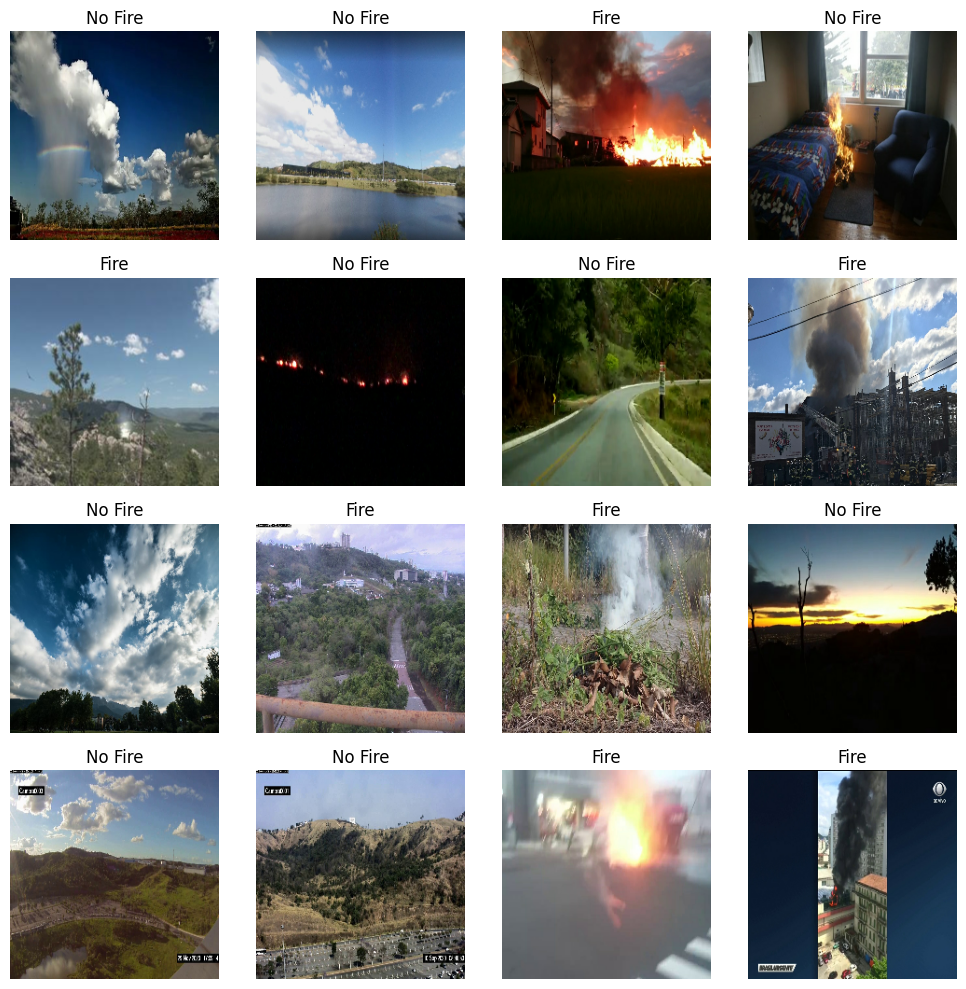

In [83]:
real_test_ds = get_dataset(REAL_TEST_IMG_DIR, real_test_labels, shuffle=False)
real_test_ds = real_test_ds.batch(32).prefetch(tf.data.AUTOTUNE)
for images, labels in real_test_ds.take(1):
    images = images.numpy()   # float32 in [0,1]
    labels = labels.numpy()

    plt.figure(figsize=(10,10))
    n = min(16, images.shape[0])
    for i in range(n):
        ax = plt.subplot(4,4,i+1)
        plt.imshow(images[i])          # <- display floats in [0,1] directly
        plt.title("Fire" if labels[i] == 1 else "No Fire")
        plt.axis("off")
    plt.tight_layout()
    plt.show()


In [183]:
test_loss, test_accuracy = model_80_20.evaluate(real_test_ds)
print(f"📊 Test Accuracy on Real Data: {test_accuracy:.4f}")
print(f"📉 Test Loss on Real Data: {test_loss:.4f}")


135/135 ━━━━━━━━━━━━━━━━━━━━ 24s 176ms/step - accuracy: 0.8431 - loss: 0.3729
📊 Test Accuracy on Real Data: 0.8502
📉 Test Loss on Real Data: 0.3562


In [184]:
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np

y_true_3 = []
y_pred_3 = []

for images, labels in real_test_ds:
    preds = model_80_20.predict(images)
    y_true_3.extend(labels.numpy())
    y_pred_3.extend((preds > 0.5).astype(int).flatten())

# Confusion matrix
cm3 = confusion_matrix(y_true_3, y_pred_3)
print("Confusion Matrix:\n", cm3)

# Classification report
print("Classification Report:\n", classification_report(y_true_3, y_pred_3, target_names=["No Fire", "Fire"]))

report_mix = classification_report(y_true_3, y_pred_3, target_names=["No Fire", "Fire"],output_dict=True)


# Extract metrics for the 'Fire' class
precision_mix = report_mix['Fire']['precision']
recall_mix = report_mix['Fire']['recall']
f1_mix = report_mix['Fire']['f1-score']
accuracy_mix = report_mix['accuracy']


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 464ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 182ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 188ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 185ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 190ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 180ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 179ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 182ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 180ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 181ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 183ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 182ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 187ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 183ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 177ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 183ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 196ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 204ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 204ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 192ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 186ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 178ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 190ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 192ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 181ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 

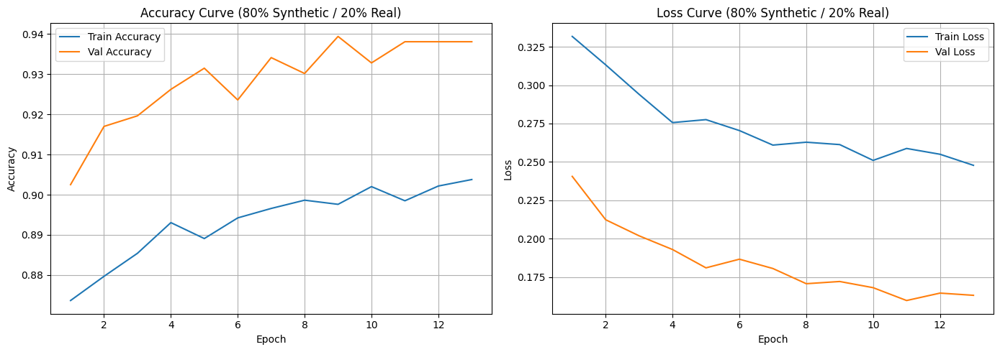

In [154]:
import matplotlib.pyplot as plt

# Example: Replace with your real history object
# history = model.history  # Or use the history from your training if saved
history = hist_80_20
# Plot accuracy and loss
def plot_training_curves(history, title=""):
    acc = history['accuracy']
    val_acc = history['val_accuracy']
    loss = history['loss']
    val_loss = history['val_loss']
    epochs = range(1, len(acc) + 1)

    plt.figure(figsize=(14, 5))

    # Accuracy plot
    plt.subplot(1, 2, 1)
    plt.plot(epochs, acc, label='Train Accuracy')
    plt.plot(epochs, val_acc, label='Val Accuracy')
    plt.title(f'Accuracy Curve {title}')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True)

    # Loss plot
    plt.subplot(1, 2, 2)
    plt.plot(epochs, loss, label='Train Loss')
    plt.plot(epochs, val_loss, label='Val Loss')
    plt.title(f'Loss Curve {title}')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

# Call the function
plot_training_curves(history, title="(80% Synthetic / 20% Real)")


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 169ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 166ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 168ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 169ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 171ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 171ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 168ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 176ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 171ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 167ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 168ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 171ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 173ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 172ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 174ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 172ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 175ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 180ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 181ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 192ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 192ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 173ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 176ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 168ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 166ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 

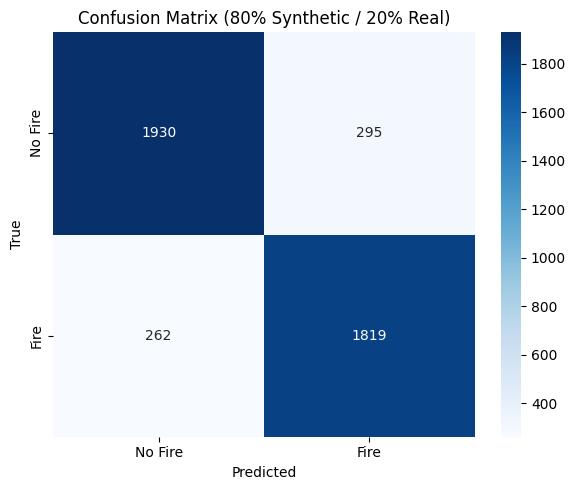

📋 Classification Report:
               precision    recall  f1-score   support

     No Fire       0.88      0.87      0.87      2225
        Fire       0.86      0.87      0.87      2081

    accuracy                           0.87      4306
   macro avg       0.87      0.87      0.87      4306
weighted avg       0.87      0.87      0.87      4306



In [116]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

# Generate predictions on real test set
y_true = []
y_pred = []

for images, labels in real_test_ds:  # Make sure real_test_ds is pre-defined
    preds = model.predict(images)
    y_true.extend(labels.numpy())
    y_pred.extend((preds > 0.5).astype(int).flatten())

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=["No Fire", "Fire"],
            yticklabels=["No Fire", "Fire"])
plt.title("Confusion Matrix (80% Synthetic / 20% Real)")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.show()

# Classification Report
report = classification_report(y_true, y_pred, target_names=["No Fire", "Fire"])
print("📋 Classification Report:\n", report)


In [156]:
# from tensorflow.keras.models import load_model

model = load_model("mobilenetv2_80_20.h5")
model.evaluate(real_test_ds)
predictions = model.predict(real_test_ds)

135/135 ━━━━━━━━━━━━━━━━━━━━ 22s 162ms/step - accuracy: 0.8431 - loss: 0.3729
135/135 ━━━━━━━━━━━━━━━━━━━━ 23s 169ms/step


## 50-50(synthetic-real)split

In [157]:
BATCH_SIZE = 32

mixed_train_ds_50 = tf.data.Dataset.sample_from_datasets(
    [real_train_ds, synthetic_train_ds],
    weights=[0.5, 0.5]
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


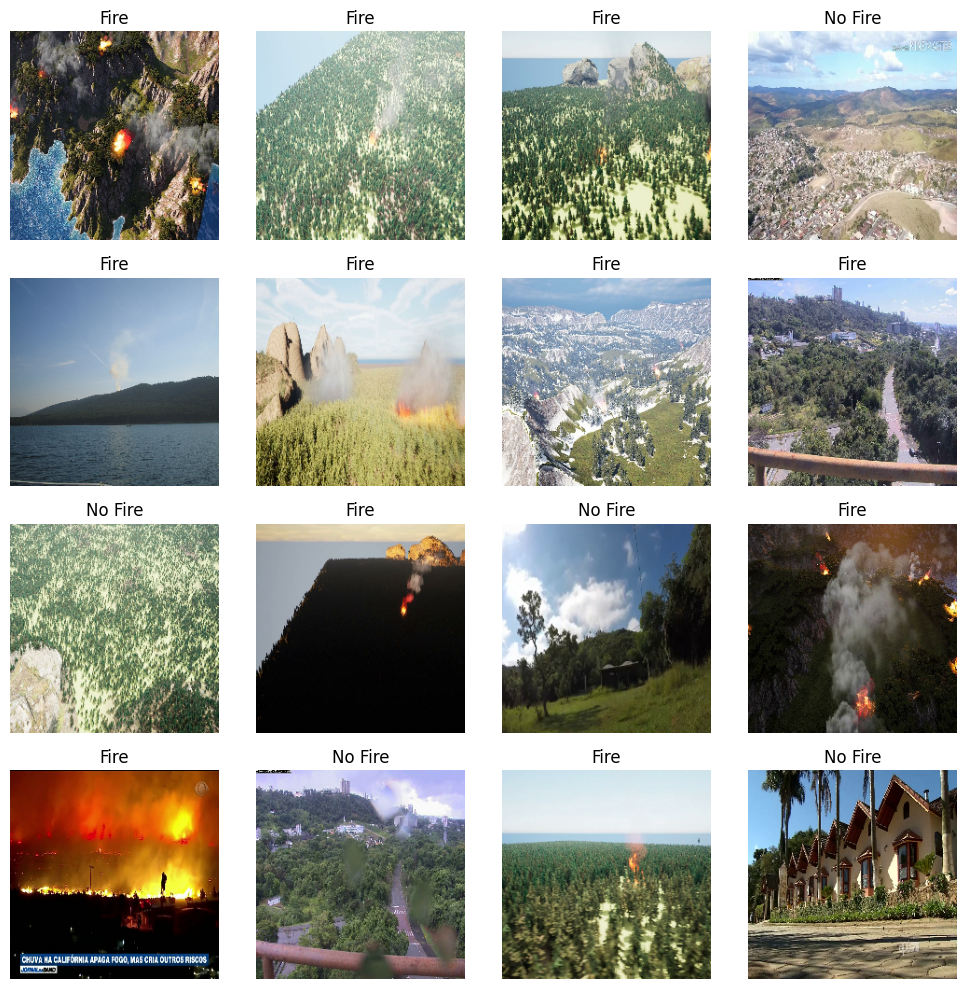

In [158]:
import matplotlib.pyplot as plt

for images, labels in mixed_train_ds_50.take(1):
    images = images.numpy()
    labels = labels.numpy()

    plt.figure(figsize=(10, 10))
    for i in range(min(16, images.shape[0])):  # show up to 16 images
        ax = plt.subplot(4, 4, i + 1)
        plt.imshow(images[i])  # shape: (224, 224, 3)
        label_text = "Fire" if labels[i] == 1 else "No Fire"
        plt.title(label_text)
        plt.axis("off")
    plt.tight_layout()
    plt.show()


In [194]:
model = load_model("mobilenetv2_fire.h5")

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)


history_50= model.fit(
    mixed_train_ds_50,
    validation_data=val_ds,  # your existing synthetic val
    epochs=20,
    callbacks=[early_stop, checkpoint]
)

model.save("mobilenetv2_fire_50.h5")

with open("history_50.json",'w') as f:
    json.dump(history_50.history,f)

Epoch 1/20
    626/Unknown 106s 156ms/step - accuracy: 0.8639 - loss: 0.3527

/opt/anaconda3/envs/data_science_projects/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:160: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: val_loss did not improve from 0.18806
626/626 ━━━━━━━━━━━━━━━━━━━━ 111s 164ms/step - accuracy: 0.8639 - loss: 0.3527 - val_accuracy: 0.7971 - val_loss: 0.4439
Epoch 2/20
626/626 ━━━━━━━━━━━━━━━━━━━━ 0s 565ms/step - accuracy: 0.8780 - loss: 0.3106
Epoch 2: val_loss did not improve from 0.18806
626/626 ━━━━━━━━━━━━━━━━━━━━ 366s 571ms/step - accuracy: 0.8780 - loss: 0.3107 - val_accuracy: 0.8669 - val_loss: 0.2963
Epoch 3/20
626/626 ━━━━━━━━━━━━━━━━━━━━ 0s 155ms/step - accuracy: 0.8827 - loss: 0.2921
Epoch 3: val_loss did not improve from 0.18806
626/626 ━━━━━━━━━━━━━━━━━━━━ 199s 305ms/step - accuracy: 0.8827 - loss: 0.2922 - val_accuracy: 0.8682 - val_loss: 0.2945
Epoch 4/20


2025-08-14 22:09:00.682722: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:452] ShuffleDatasetV3:17725: Filling up shuffle buffer (this may take a while): 9938 of 10000
2025-08-14 22:09:00.745028: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:482] Shuffle buffer filled.


626/626 ━━━━━━━━━━━━━━━━━━━━ 0s 373ms/step - accuracy: 0.8889 - loss: 0.2895
Epoch 4: val_loss did not improve from 0.18806
626/626 ━━━━━━━━━━━━━━━━━━━━ 252s 380ms/step - accuracy: 0.8889 - loss: 0.2896 - val_accuracy: 0.8893 - val_loss: 0.2609
Epoch 5/20
626/626 ━━━━━━━━━━━━━━━━━━━━ 0s 162ms/step - accuracy: 0.8903 - loss: 0.2887
Epoch 5: val_loss did not improve from 0.18806
626/626 ━━━━━━━━━━━━━━━━━━━━ 114s 169ms/step - accuracy: 0.8903 - loss: 0.2887 - val_accuracy: 0.8972 - val_loss: 0.2562
Epoch 6/20
626/626 ━━━━━━━━━━━━━━━━━━━━ 0s 168ms/step - accuracy: 0.8925 - loss: 0.2787
Epoch 6: val_loss did not improve from 0.18806
626/626 ━━━━━━━━━━━━━━━━━━━━ 118s 175ms/step - accuracy: 0.8925 - loss: 0.2787 - val_accuracy: 0.8893 - val_loss: 0.2492
Epoch 7/20
626/626 ━━━━━━━━━━━━━━━━━━━━ 0s 172ms/step - accuracy: 0.8910 - loss: 0.2772
Epoch 7: val_loss did not improve from 0.18806
626/626 ━━━━━━━━━━━━━━━━━━━━ 122s 180ms/step - accuracy: 0.8910 - loss: 0.2772 - val_accuracy: 0.8946 - val_

In [53]:
from tensorflow.keras.models import load_model
model = load_model("mobilenetv2_fire_50.h5")

with open("history_50.json",'r') as f:
    history_50 = json.load(f)

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.evaluate(real_test_ds)

135/135 ━━━━━━━━━━━━━━━━━━━━ 23s 169ms/step - accuracy: 0.8536 - loss: 0.3478


[0.3388342559337616, 0.8576405048370361]

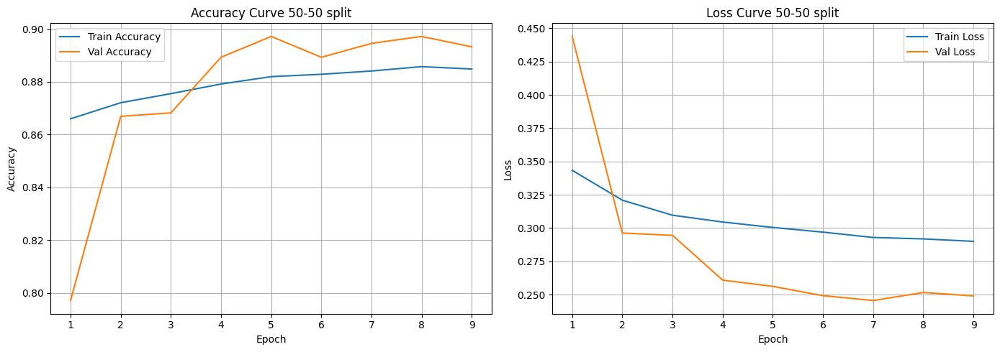

In [196]:
plot_training_curves(history_50,"50-50 split")

In [51]:
# from sklearn.metrics import classification_report, confusion_matrix
# import numpy as np
# import seaborn as sns
# import matplotlib.pyplot as plt

# Evaluate model on real test set
test_loss, test_accuracy = model.evaluate(real_test_ds)
print(f" Test Accuracy on Real Data: {test_accuracy:.4f}")
print(f" Test Loss on Real Data: {test_loss:.4f}")

# Predictions
y_true = []
y_pred = []

for images, labels in real_test_ds:
    preds = model.predict(images)
    y_true.extend(labels.numpy())
    y_pred.extend((preds > 0.5).astype(int).flatten())




135/135 ━━━━━━━━━━━━━━━━━━━━ 23s 171ms/step - accuracy: 0.8536 - loss: 0.3478
📊 Test Accuracy on Real Data: 0.8576
📉 Test Loss on Real Data: 0.3388
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 421ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 170ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 174ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 184ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 185ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 192ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 181ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 172ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 183ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 188ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 170ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 199ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 188ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 189ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 177ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 172ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 191ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 197ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 196ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 202ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 202ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 177ms

2025-09-03 19:36:27.227331: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [161]:
print("\n Classification Report:\n",classification_report(y_true, y_pred, target_names=["No Fire", "Fire"]))
report = classification_report(y_true, y_pred, target_names=["No Fire", "Fire"],output_dict=True)





 Classification Report:
               precision    recall  f1-score   support

     No Fire       0.88      0.87      0.87      2225
        Fire       0.86      0.87      0.87      2081

    accuracy                           0.87      4306
   macro avg       0.87      0.87      0.87      4306
weighted avg       0.87      0.87      0.87      4306



In [162]:
#  Dynamically extract metrics for Fire class
acc_50_50 = report['accuracy']
precision_50_50 = report['Fire']['precision']
recall_50_50 = report['Fire']['recall']
f1_50_50 = report['Fire']['f1-score']

#  Save results dynamically for comparison
results_50_50 = {
    "accuracy": acc_50_50,
    "precision": precision_50_50,
    "recall": recall_50_50,
    "f1_score": f1_50_50
}

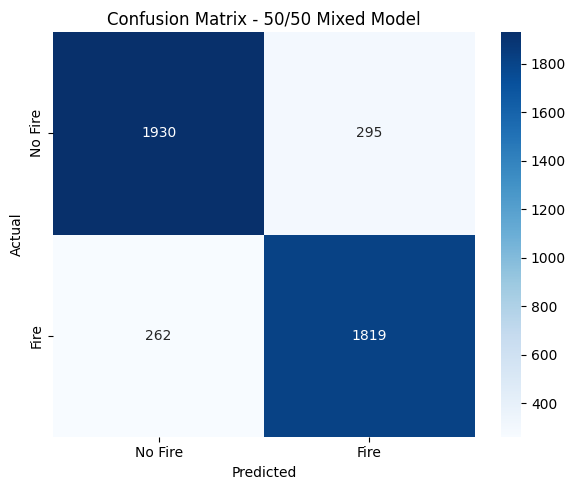

In [200]:
#  Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["No Fire", "Fire"], yticklabels=["No Fire", "Fire"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - MobileNetV2 - 50% Synthetic/50% Real ")
plt.tight_layout()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 170ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 156ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 154ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 156ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 152ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 162ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 153ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 157ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 151ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 152ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 160ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 156ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 156ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 151ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 152ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 161ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 157ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 154ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 155ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 159ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 153ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 157ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 152ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 155ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 

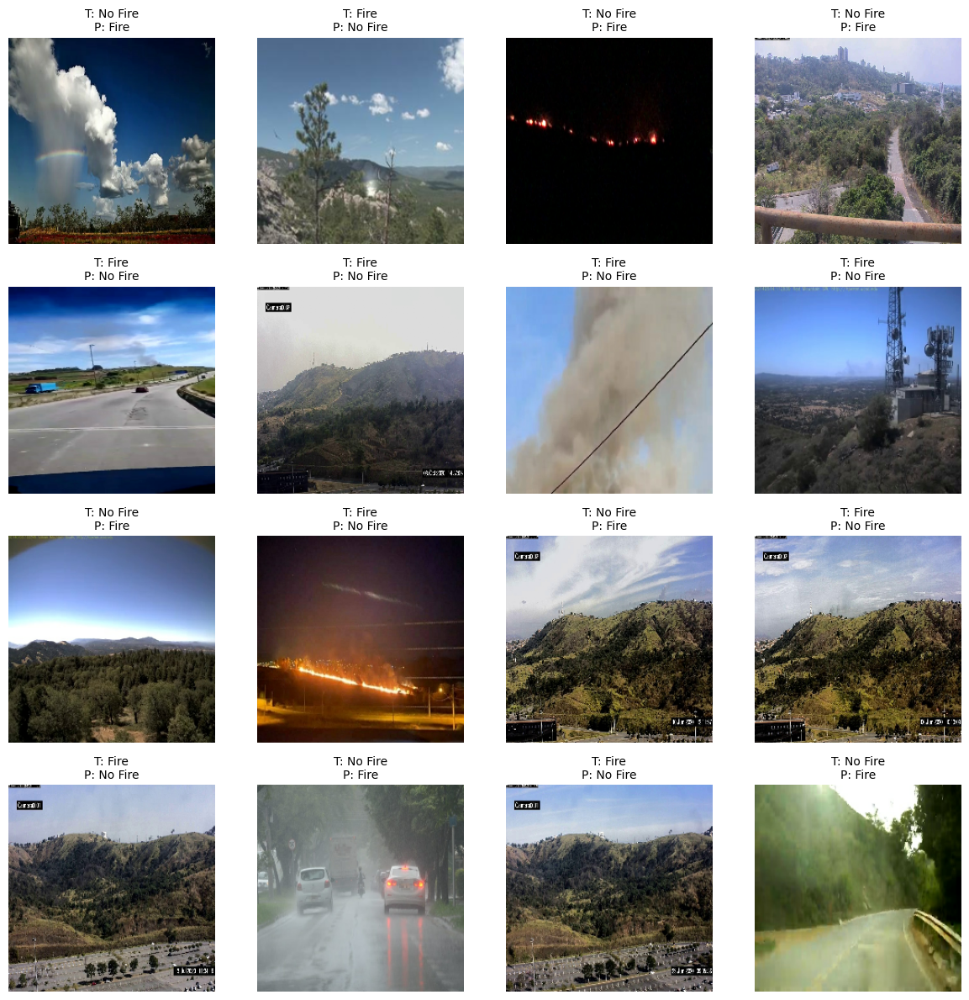

In [84]:

# Collect all predictions and labels with image references
y_true = []
y_pred = []
all_images = []

for images, labels in real_test_ds:
    preds = model.predict(images)
    y_true.extend(labels.numpy())
    y_pred.extend((preds > 0.5).astype(int).flatten())
    all_images.extend(images.numpy())

y_true = np.array(y_true)
y_pred = np.array(y_pred)
all_images = np.array(all_images)

# Find misclassified indices
mis_idx = np.where(y_true != y_pred)[0]
print(f"Total misclassified examples: {len(mis_idx)}")

# Plot some misclassified examples
plt.figure(figsize=(12, 12))
for i, idx in enumerate(mis_idx[:16]):  # show up to 16 misclassified
    ax = plt.subplot(4, 4, i + 1)
    plt.imshow(all_images[idx])
    true_label = "Fire" if y_true[idx] == 1 else "No Fire"
    pred_label = "Fire" if y_pred[idx] == 1 else "No Fire"
    plt.title(f"T: {true_label}\nP: {pred_label}", fontsize=10)
    plt.axis("off")
plt.tight_layout()
plt.show()

## 20-80 (synthetic- Real)

In [58]:
# Paths
REAL_IMG_DIR = f"{DATA_ROOT}/real/train/images"
REAL_LAB_DIR = f"{DATA_ROOT}/real/train/labels"
SYN_IMG_DIR = f"{DATA_ROOT}/synthetic/train"
SYN_LABEL_FILE = f"{DATA_ROOT}/synthetic/train/Labels.txt"

# Parse real (YOLO .txt) labels
def parse_yolo_labels(label_folder):
    label_dict = {}
    for file in os.listdir(label_folder):
        if file.endswith(".txt"):
            path = os.path.join(label_folder, file)
            with open(path, 'r') as f:
                lines = f.readlines()
                image_name = file.replace(".txt", ".jpg")
                label = 0
                for line in lines:
                    if line.strip().startswith("0"):
                        label = 1
                        break
                label_dict[image_name] = label
    return label_dict

# Parse synthetic labels
def parse_label_file(label_file_path):
    label_dict = {}
    with open(label_file_path, 'r') as f:
        for line in f:
            parts = line.strip().split()
            if not parts:
                continue
            image_name = parts[0]
            label = 0
            for box in parts[1:]:
                if int(box.split(',')[-1]) == 0:
                    label = 1
                    break
            label_dict[image_name] = label
    return label_dict

# Load label dictionaries
real_labels = parse_yolo_labels(REAL_LAB_DIR)
synthetic_labels = parse_label_file(SYN_LABEL_FILE)


In [59]:
def process_image(path):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, [224, 224])
    img = img / 255.0
    return img

def get_dataset(img_dir, label_dict, shuffle=True):
    paths, labels = [], []
    for fname in os.listdir(img_dir):
        if fname.endswith(".jpg") and fname in label_dict:
            paths.append(os.path.join(img_dir, fname))
            labels.append(label_dict[fname])

    path_ds = tf.data.Dataset.from_tensor_slices(paths)
    label_ds = tf.data.Dataset.from_tensor_slices(labels)
    img_ds = path_ds.map(process_image, num_parallel_calls=tf.data.AUTOTUNE)

    ds = tf.data.Dataset.zip((img_ds, label_ds))
    if shuffle:
        ds = ds.shuffle(1000)

    return ds


In [61]:
BATCH_SIZE = 32

# Load datasets
synthetic_ds = get_dataset(SYN_IMG_DIR, synthetic_labels)
real_ds = get_dataset(REAL_IMG_DIR, real_labels)

# Calculate sizes
real_size = tf.data.experimental.cardinality(real_ds).numpy()
synthetic_size = tf.data.experimental.cardinality(synthetic_ds).numpy()

# Compute split (20% synthetic, 80% real)
num_total = min(real_size, synthetic_size * 4)  # to ensure 20/80 balance
num_synthetic = int(0.2 * num_total)
num_real = num_total - num_synthetic

# Trim
synthetic_trimmed = synthetic_ds.take(num_synthetic)
real_trimmed = real_ds.take(num_real)

# Combine
mixed_20_80_ds = synthetic_trimmed.concatenate(real_trimmed)
mixed_20_80_ds = mixed_20_80_ds.shuffle(10000).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


In [204]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Model

model = load_model("mobilenetv2_fire.h5")
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# # Callbacks
early_stop = EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True, verbose=1)
checkpoint = ModelCheckpoint("mobilenetv2_20synthetic_best.h5", monitor="val_loss", save_best_only=True, verbose=1)



In [205]:
# Reuse validation set from synthetic if available
val_ds = get_dataset(f"{DATA_ROOT}/synthetic/valid", 
                     parse_label_file(f"{DATA_ROOT}/synthetic/valid/Labels.txt"),
                     shuffle=False).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

history_20_80 = model.fit(
    mixed_20_80_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[early_stop, checkpoint]
)


model.save("mobilenetv2_fire_20_80.h5")

with open("history_20_80.json",'w') as f:
    json.dump(history_20_80.history,f)



Epoch 1/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 0s 179ms/step - accuracy: 0.8553 - loss: 0.3783
Epoch 1: val_loss improved from inf to 0.26062, saving model to mobilenetv2_20synthetic_best.h5


351/351 ━━━━━━━━━━━━━━━━━━━━ 77s 194ms/step - accuracy: 0.8553 - loss: 0.3782 - val_accuracy: 0.8946 - val_loss: 0.2606
Epoch 2/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 0s 176ms/step - accuracy: 0.8712 - loss: 0.3184
Epoch 2: val_loss improved from 0.26062 to 0.23469, saving model to mobilenetv2_20synthetic_best.h5


351/351 ━━━━━━━━━━━━━━━━━━━━ 75s 189ms/step - accuracy: 0.8712 - loss: 0.3184 - val_accuracy: 0.8959 - val_loss: 0.2347
Epoch 3/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 0s 176ms/step - accuracy: 0.8819 - loss: 0.3080
Epoch 3: val_loss did not improve from 0.23469
351/351 ━━━━━━━━━━━━━━━━━━━━ 75s 189ms/step - accuracy: 0.8819 - loss: 0.3080 - val_accuracy: 0.8893 - val_loss: 0.2554
Epoch 4/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 0s 177ms/step - accuracy: 0.8863 - loss: 0.2915
Epoch 4: val_loss improved from 0.23469 to 0.21216, saving model to mobilenetv2_20synthetic_best.h5


351/351 ━━━━━━━━━━━━━━━━━━━━ 76s 192ms/step - accuracy: 0.8863 - loss: 0.2915 - val_accuracy: 0.9144 - val_loss: 0.2122
Epoch 5/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 0s 178ms/step - accuracy: 0.8908 - loss: 0.2918
Epoch 5: val_loss improved from 0.21216 to 0.21147, saving model to mobilenetv2_20synthetic_best.h5


351/351 ━━━━━━━━━━━━━━━━━━━━ 76s 192ms/step - accuracy: 0.8907 - loss: 0.2918 - val_accuracy: 0.9144 - val_loss: 0.2115
Epoch 6/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 0s 177ms/step - accuracy: 0.8916 - loss: 0.2866
Epoch 6: val_loss improved from 0.21147 to 0.20513, saving model to mobilenetv2_20synthetic_best.h5


351/351 ━━━━━━━━━━━━━━━━━━━━ 76s 191ms/step - accuracy: 0.8916 - loss: 0.2866 - val_accuracy: 0.9157 - val_loss: 0.2051
Epoch 7/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 0s 451ms/step - accuracy: 0.8940 - loss: 0.2782
Epoch 7: val_loss improved from 0.20513 to 0.20372, saving model to mobilenetv2_20synthetic_best.h5


351/351 ━━━━━━━━━━━━━━━━━━━━ 171s 463ms/step - accuracy: 0.8940 - loss: 0.2783 - val_accuracy: 0.9196 - val_loss: 0.2037
Epoch 8/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 0s 155ms/step - accuracy: 0.8938 - loss: 0.2788
Epoch 8: val_loss did not improve from 0.20372
351/351 ━━━━━━━━━━━━━━━━━━━━ 66s 167ms/step - accuracy: 0.8938 - loss: 0.2788 - val_accuracy: 0.9130 - val_loss: 0.2125
Epoch 9/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 0s 166ms/step - accuracy: 0.8979 - loss: 0.2663
Epoch 9: val_loss did not improve from 0.20372
351/351 ━━━━━━━━━━━━━━━━━━━━ 71s 179ms/step - accuracy: 0.8979 - loss: 0.2663 - val_accuracy: 0.9170 - val_loss: 0.2063
Epoch 9: early stopping
Restoring model weights from the end of the best epoch: 7.


In [164]:
# model.save("mobilenetv2_mixed_20_80.h5")  # Modern format

model = load_model("mobilenetv2_fire_20_80.h5")

with open("history_20_80.json",'r') as f:
    history_20_80 = json.load(f)

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)


In [133]:
history_20_80['accuracy']

[0.8608136773109436,
 0.8736616969108582,
 0.88160240650177,
 0.884814441204071,
 0.8874911069869995,
 0.8904353976249695,
 0.8904353976249695,
 0.893915057182312,
 0.8943611979484558]

In [62]:
REAL_TEST_IMG = f"{DATA_ROOT}/real/test/images"
REAL_TEST_LAB = f"{DATA_ROOT}/real/test/labels"
real_test_labels = parse_yolo_labels(REAL_TEST_LAB)

real_test_ds = get_dataset(REAL_TEST_IMG, real_test_labels, shuffle=False)
real_test_ds = real_test_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)



In [ ]:
test_loss, test_accuracy = model.evaluate(real_test_ds)
print(f"✅ Test Accuracy (Real): {test_accuracy:.4f}")
print(f"📉 Test Loss (Real): {test_loss:.4f}")


In [166]:
y_true, y_pred = [], []

for images, labels in real_test_ds:
    preds = model.predict(images)
    y_pred.extend((preds > 0.5).astype(int).flatten())
    y_true.extend(labels.numpy().flatten())

# Report
print(classification_report(y_true, y_pred, target_names=["No Fire", "Fire"]))

report = classification_report(y_true, y_pred, target_names=["No Fire", "Fire"],output_dict=True)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 405ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 159ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 162ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 161ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 161ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 162ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 163ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 164ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 166ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 160ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 158ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 164ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 158ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 159ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 162ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 163ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 166ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 164ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 164ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 165ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 162ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 166ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 161ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 162ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 168ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 

In [167]:
acc_20_80 = report['accuracy']
precision_20_80 = report['Fire']['precision']
recall_20_80 = report['Fire']['recall']
f1_20_80 = report['Fire']['f1-score']

#  Save results dynamically for comparison
results_20_80 = {
    "accuracy": acc_20_80,
    "precision": precision_20_80,
    "recall": recall_20_80,
    "f1_score": f1_20_80}

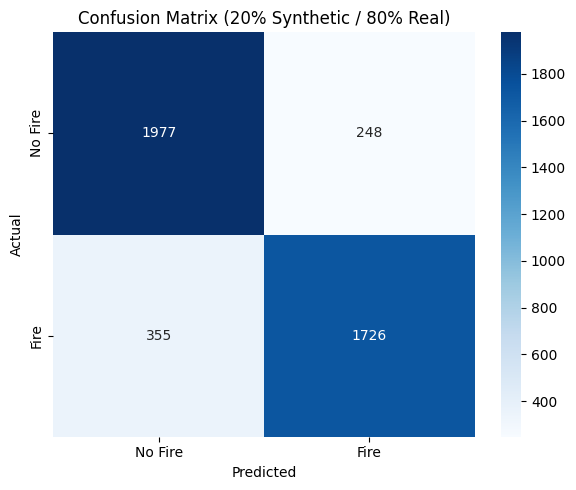

In [210]:

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=["No Fire", "Fire"], yticklabels=["No Fire", "Fire"])
plt.title("Confusion Matrix (20% Synthetic / 80% Real)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

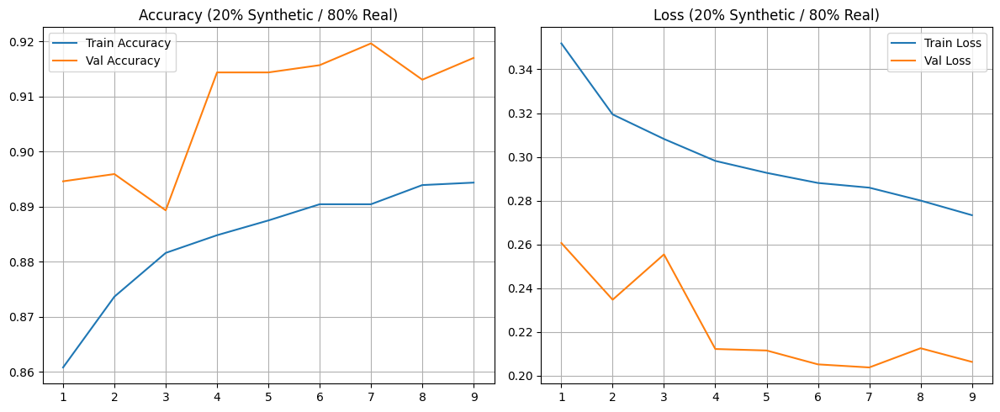

In [124]:


acc = history_20_80['accuracy']
val_acc = history_20_80['val_accuracy']
loss = history_20_80['loss']
val_loss = history_20_80['val_loss']
epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(12,5))

# Accuracy
plt.subplot(1,2,1)
plt.plot(epochs_range, acc, label='Train Accuracy')
plt.plot(epochs_range, val_acc, label='Val Accuracy')
plt.title('Accuracy (20% Synthetic / 80% Real)')
plt.legend()
plt.grid(True)

# Loss
plt.subplot(1,2,2)
plt.plot(epochs_range, loss, label='Train Loss')
plt.plot(epochs_range, val_loss, label='Val Loss')
plt.title('Loss (20% Synthetic / 80% Real)')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


In [16]:

# Replace values with your actual test evaluation results
comparison_df = pd.DataFrame({
    "Split": ["100% Real", "100% Synthetic", "80% Synthetic / 20% Real","50% Synthetic/50% Real","20% Synthetic/80% Real"],
    "Accuracy": [accuracy_real, accuracy_syn, accuracy_mix,acc_50_50,acc_20_80],
    "Precision (Fire)": [precision_real, precision_syn,precision_mix,precision_50_50,precision_20_80],
    "Recall (Fire)": [recall_real,recall_syn,recall_mix,recall_50_50,recall_20_80],
    "F1-Score (Fire)": [f1_real, f1_syn, f1_mix,f1_50_50,f1_20_80],
})

# Display in notebook
display(comparison_df)

# comparision_df.to_csv("light_metrics.csv",index=False)

In [187]:
comparison_df.to_csv("light_metrics.csv",index=False)

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


comparison_df = pd.read_csv("light_metrics.csv")

In [12]:

# Assuming your dataframe is named df
order = [
    "100% Real",
    "20% Synthetic/80% Real",
    "50% Synthetic/50% Real",
    "80% Synthetic / 20% Real",
    "100% Synthetic"
]

# Reorder using categorical
comparison_df["Split"] = pd.Categorical(comparison_df["Split"], categories=order, ordered=True)
comparison_df = comparison_df.sort_values("Split").reset_index(drop=True)

In [13]:
comparison_df

,Split,Accuracy,Precision (Fire),Recall (Fire),F1-Score (Fire)
0,100% Real,0.886670,0.924193,0.858322,0.890041
1,20% Synthetic/80% Real,0.859963,0.874367,0.829409,0.851295
2,50% Synthetic/50% Real,0.870646,0.860454,0.874099,0.867223
3,80% Synthetic / 20% Real,0.850209,0.831793,0.864969,0.848057
4,100% Synthetic,0.813980,0.813283,0.846154,0.829393


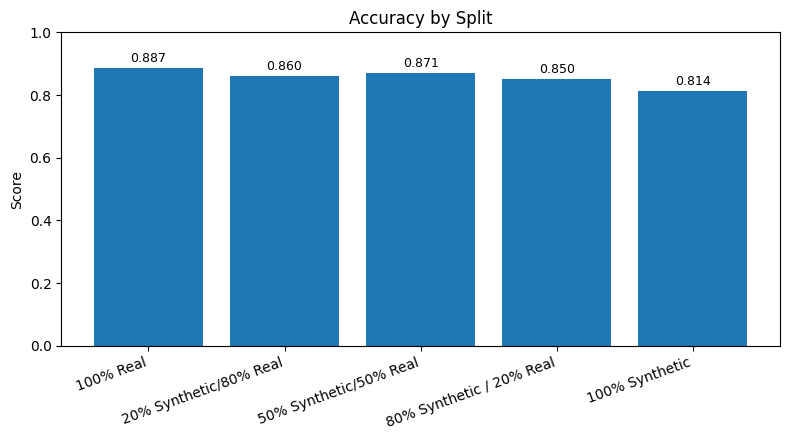

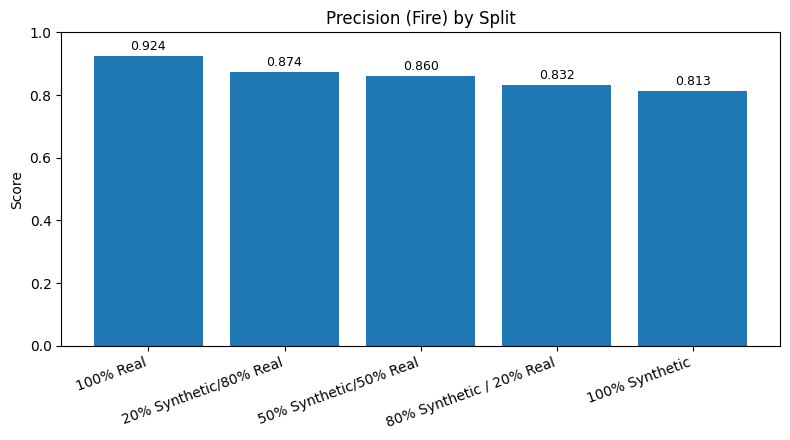

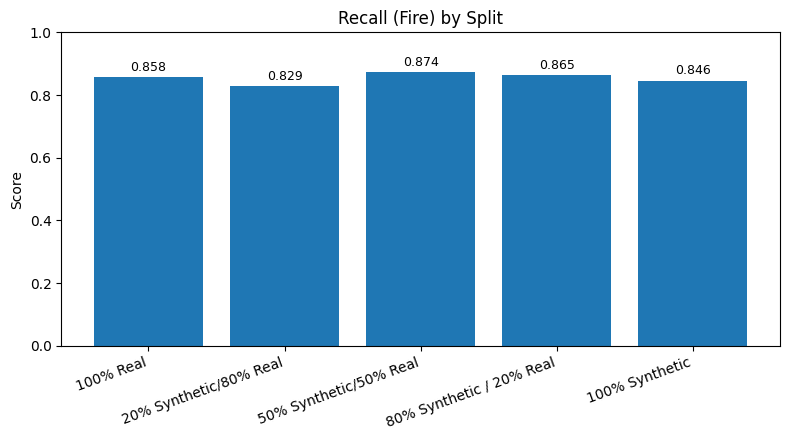

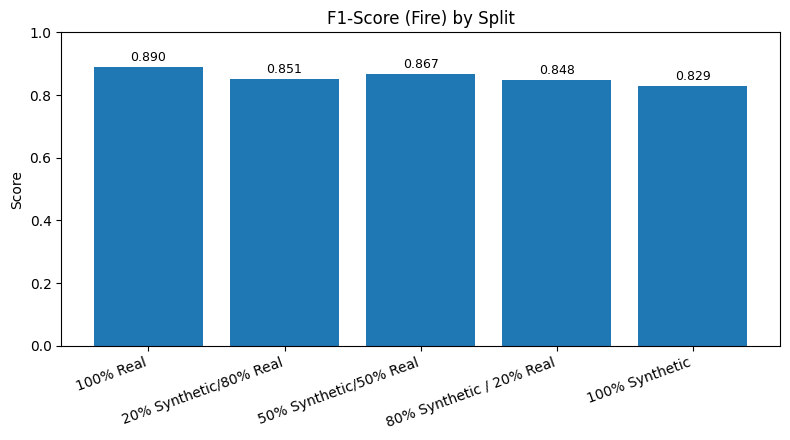

In [14]:

# Ensure the splits appear in the original order
splits = comparison_df["Split"].tolist()

def plot_metric(df, metric_col, title, ylabel="Score", ylim=(0, 1.0)):
    values = df[metric_col].values
    x = np.arange(len(values))

    plt.figure(figsize=(8, 4.5))
    bars = plt.bar(x, values)  # no explicit colors (per your rules)
    plt.xticks(x, splits, rotation=20, ha="right")
    plt.ylim(*ylim)
    plt.ylabel(ylabel)
    plt.title(title)

    # Add value labels on top of bars
    for rect, v in zip(bars, values):
        plt.text(rect.get_x() + rect.get_width()/2, rect.get_height() + 0.01,
                 f"{v:.3f}", ha="center", va="bottom", fontsize=9)

    plt.tight_layout()
    plt.show()

# Plot each metric on its own figure (no subplots)
plot_metric(comparison_df, "Accuracy", "Accuracy by Split")
plot_metric(comparison_df, "Precision (Fire)", "Precision (Fire) by Split")
plot_metric(comparison_df, "Recall (Fire)", "Recall (Fire) by Split")
plot_metric(comparison_df, "F1-Score (Fire)", "F1-Score (Fire) by Split")

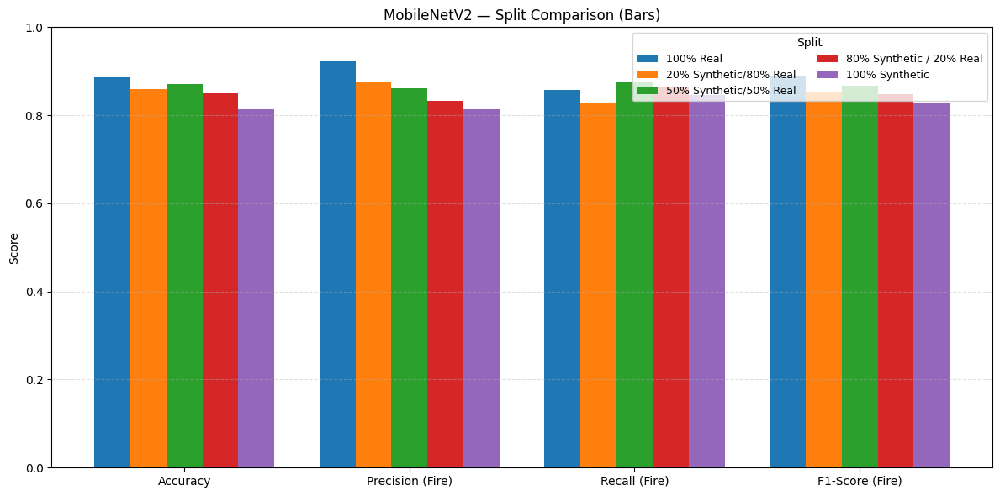

In [15]:

def plot_grouped_bars(df, title="MobileNetV2 — Split Comparison (Bars)"):
    metrics = ["Accuracy", "Precision (Fire)", "Recall (Fire)", "F1-Score (Fire)"]
    df = df.dropna(subset=metrics)
    splits = df["Split"].tolist()
    M = len(metrics)
    S = len(splits)

    # Values S x M
    vals = df[metrics].values.astype(float)  # rows = splits, cols = metrics

    x = np.arange(M)  # metric positions
    width = 0.8 / max(S, 1)  # bar width so all splits fit within 0.8 span

    plt.figure(figsize=(12, 6))
    for i, split in enumerate(splits):
        plt.bar(x + i*width, vals[i], width=width, label=split)

    plt.xticks(x + width*(S-1)/2, metrics, rotation=0)
    plt.ylim(0, 1.0)
    plt.ylabel("Score")
    plt.title(title)
    plt.grid(axis="y", linestyle="--", alpha=0.4)
    plt.legend(title="Split", ncol=2, fontsize=9)
    plt.tight_layout()
    plt.show()

# ---- call it ----
plot_grouped_bars(comparison_df)

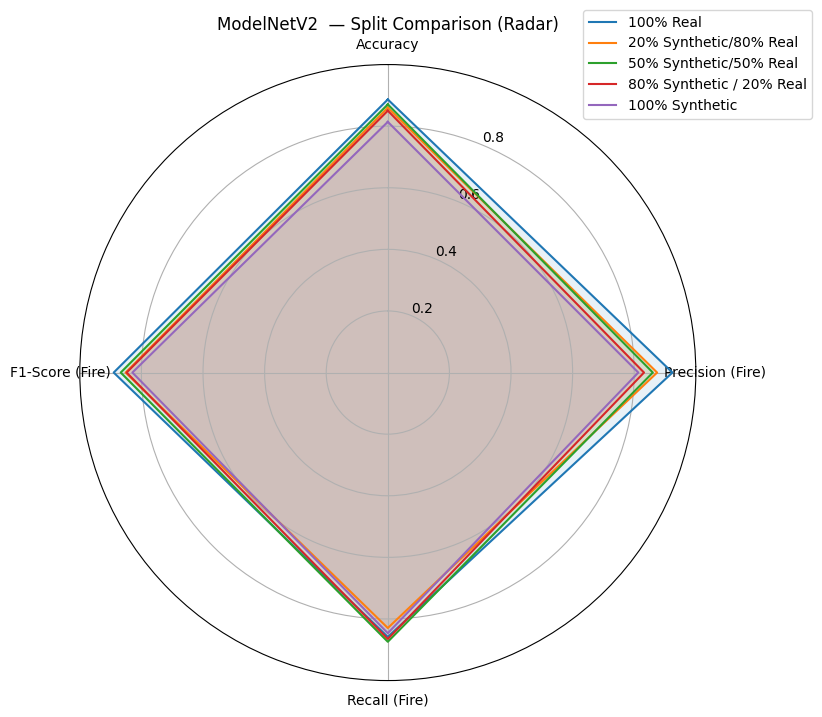

In [17]:

metrics = ["Accuracy", "Precision (Fire)", "Recall (Fire)", "F1-Score (Fire)"]

# Normalize data for radar
num_vars = len(metrics)
angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()
angles += angles[:1]  # complete the loop

fig = plt.figure(figsize=(8, 8))
ax = plt.subplot(111, polar=True)

for i, row in comparison_df.iterrows():
    values = row[metrics].tolist()
    values += values[:1]  # close the shape
    ax.plot(angles, values, label=row["Split"])
    ax.fill(angles, values, alpha=0.1)

ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)
ax.set_xticks(angles[:-1])
ax.set_xticklabels(metrics)
ax.set_yticks([0.2, 0.4, 0.6, 0.8])
ax.set_yticklabels(["0.2", "0.4", "0.6", "0.8"])
ax.set_ylim(0, 1)
plt.legend(loc='upper right', bbox_to_anchor=(1.2, 1.1))
plt.title("ModelNetV2  — Split Comparison (Radar)")
plt.show()

# DenseNet121 model

In [26]:
import os, json, numpy as np, matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras import layers, models
from tensorflow.keras.models import load_model
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from sklearn.metrics import classification_report, confusion_matrix

BATCH_SIZE = 32


In [27]:
# ==== Dataset helpers to avoid double-batching ====

def is_batched(ds):
    """Return True if dataset yields (None, H, W, C)."""
    img_spec = ds.element_spec[0]  # (image, label)
    return (img_spec.shape.rank == 4) and (img_spec.shape[0] is None)

def ensure_batched(ds, batch_size=32):
    """Batch only if needed, always prefetch."""
    if is_batched(ds):
        return ds.prefetch(tf.data.AUTOTUNE)
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)


In [80]:
def build_densenet_model():
    base = DenseNet121(input_shape=(224,224,3), include_top=False, weights="imagenet")
    base.trainable = False
    model = models.Sequential([base, layers.GlobalAveragePooling2D(), layers.Dense(1, activation="sigmoid")])
    model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    return model

# def train_or_load(model_path, train_ds, val_ds, epochs=20):
#     """
#     Loads model if file exists; otherwise trains once, saves model + history.
#     Returns (model, history_dict_or_None).
#     """
#     if os.path.exists(model_path):
#         print(f" Loaded saved model: {model_path}")
#         model = load_model(model_path)
#         return model, None

#     print(" Training DenseNet121 from scratch...")
#     model = build_densenet_model()
#     es = EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True, verbose=1)
#     ck = ModelCheckpoint(model_path, monitor="val_loss", save_best_only=True, verbose=1)

#     hist = model.fit(train_ds, validation_data=val_ds, epochs=epochs, callbacks=[es, ck])
#     # Always keep a JSON history for plotting without retraining
#     hist_path = model_path.replace(".h5", ".json").replace(".keras", ".json")
#     with open(hist_path, "w") as f:
#         json.dump(hist.history, f)
#     return model, hist.history

from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau, Callback

class OverfittingStop(Callback):
    """
    Stop when val_loss worsens while train_loss improves for `patience` epochs,
    AND/OR when the generalization gap exceeds `gap_threshold`.
    """
    def __init__(self, patience=2, gap_threshold=0.10):
        super().__init__()
        self.patience = patience
        self.gap_threshold = gap_threshold
        self.bad_epochs = 0

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        loss     = logs.get("loss")
        val_loss = logs.get("val_loss")

        # need both to decide
        if loss is None or val_loss is None:
            return

        gap = val_loss - loss  # >0 means val worse than train

        # condition 1: widening overfitting (val up / train down)
        # we approximate by: current val_loss > best so far, AND current loss < previous loss
        # keras gives best val via self.model.history; keep our own best_val
        if not hasattr(self, "_best_val"):
            self._best_val = val_loss
            self._prev_loss = loss
            return

        widening = (val_loss > self._best_val) and (loss < self._prev_loss)
        large_gap = (gap > self.gap_threshold)

        if widening or large_gap:
            self.bad_epochs += 1
        else:
            self.bad_epochs = 0

        # update trackers
        self._best_val  = min(self._best_val, val_loss)
        self._prev_loss = loss

        if self.bad_epochs >= self.patience:
            print(f"\n⛔ Stopping early: overfitting detected "
                  f"(bad_epochs={self.bad_epochs}, gap={gap:.3f}).")
            self.model.stop_training = True

def train_or_load(model_path, train_ds, val_ds, max_epochs=100,
                  es_patience=3, es_min_delta=1e-4,
                  gap_patience=2, gap_threshold=0.10):
    """
    Loads model if file exists; otherwise trains until overfitting signs appear.
    - EarlyStopping on val_loss (patience/min_delta) with restore_best_weights.
    - OverfittingStop on widening generalization gap.
    - ReduceLROnPlateau to help avoid premature plateaus.
    Saves best model + history JSON.
    """
    if os.path.exists(model_path):
        print(f" Loaded saved model: {model_path}")
        model = load_model(model_path)
        return model, None

    print(" Training DenseNet121 from scratch...")
    model = build_densenet_model()

    es = EarlyStopping(
        monitor="val_loss",
        patience=es_patience,     # epochs with no val_loss improvement
        min_delta=es_min_delta,   # required improvement magnitude
        restore_best_weights=True,
        verbose=1
    )
    ck = ModelCheckpoint(
        model_path,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
    # optional but helpful for stability
    rlrop = ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=1,
        min_lr=1e-6,
        verbose=1
    )
    of = OverfittingStop(
        patience=gap_patience,
        gap_threshold=gap_threshold  # e.g., stop if (val_loss - loss) > 0.10 for `gap_patience` epochs
    )

    hist = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=max_epochs,
        callbacks=[es, rlrop, of, ck],
        verbose=1
    )

    # Always keep JSON history for plotting without retraining
    hist_path = model_path.replace(".h5", ".json").replace(".keras", ".json")
    with open(hist_path, "w") as f:
        json.dump(hist.history, f)

    return model, hist.history

In [61]:
def evaluate_on_real(model, real_test_batched, split_name, plot_cm=True):
    y_true, y_pred = [], []
    for imgs, labs in real_test_batched:
        pr = model.predict(imgs, verbose=0)
        y_true.extend(labs.numpy().tolist())
        y_pred.extend((pr > 0.5).astype(int).flatten().tolist())

    rep = classification_report(y_true, y_pred, target_names=["No Fire","Fire"], output_dict=True)
    print(f"\n {split_name} — Classification Report")
    print(classification_report(y_true, y_pred, target_names=["No Fire","Fire"]))

    if plot_cm:
        cm = confusion_matrix(y_true, y_pred)
        plt.figure(figsize=(6,5))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                    xticklabels=["No Fire","Fire"], yticklabels=["No Fire","Fire"])
        plt.title(f"Confusion Matrix — {split_name}")
        plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.tight_layout(); plt.show()

    return {
        "Split": split_name,
        "Accuracy": rep["accuracy"],
        "Precision (Fire)": rep["Fire"]["precision"],
        "Recall (Fire)": rep["Fire"]["recall"],
        "F1-Score (Fire)": rep["Fire"]["f1-score"]
    }


In [54]:
def plot_history_from_path(model_path, title_suffix=""):
    hist_path = model_path.replace(".h5", ".json").replace(".keras", ".json")
    if not os.path.exists(hist_path):
        print(f" No history file found at {hist_path}.")
        return
    with open(hist_path, "r") as f:
        hist = json.load(f)

    acc, val_acc = hist.get("accuracy", []), hist.get("val_accuracy", [])
    loss, val_loss = hist.get("loss", []), hist.get("val_loss", [])
    epochs = range(1, len(acc)+1)

    plt.figure(figsize=(14,5))
    # Acc
    plt.subplot(1,2,1)
    if acc: plt.plot(epochs, acc, label="Train Acc")
    if val_acc: plt.plot(epochs, val_acc, label="Val Acc")
    plt.title(f"Accuracy {title_suffix}"); plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.grid(True); plt.legend()
    # Loss
    plt.subplot(1,2,2)
    if loss: plt.plot(epochs, loss, label="Train Loss")
    if val_loss: plt.plot(epochs, val_loss, label="Val Loss")
    plt.title(f"Loss {title_suffix}"); plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.grid(True); plt.legend()
    plt.tight_layout(); plt.show()


In [31]:
# 👇 pick the validation dataset you already used earlier
VAL_DS = val_ds        # or: syn_valid_ds

# Make sure these exist from your earlier code:
# - real_train_ds (UNBATCHED)
# - real_test_ds  (UNBATCHED or BATCHED)


In [42]:
BATCH_SIZE = 32

train_batched       = ensure_batched(real_train_ds, BATCH_SIZE)  # 100% real training
val_batched         = ensure_batched(VAL_DS, BATCH_SIZE)         # your chosen validation
real_test_batched   = ensure_batched(real_test_ds, BATCH_SIZE)   # REAL test set (for final eval)


# 100% REAL

In [66]:
# ==== 100% REAL with DenseNet121 ====
model_path_real = "densenet121_real_only.keras"

model_real, hist_real_dict = train_or_load(
    model_path=model_path_real,
    train_ds=train_batched,
    val_ds=val_batched,
    # epochs=20
)




 Training DenseNet121 from scratch...
Epoch 1/100
539/539 ━━━━━━━━━━━━━━━━━━━━ 0s 677ms/step - accuracy: 0.6646 - loss: 0.6054
Epoch 1: val_loss improved from inf to 0.64112, saving model to densenet121_real_only.keras
539/539 ━━━━━━━━━━━━━━━━━━━━ 392s 711ms/step - accuracy: 0.6647 - loss: 0.6053 - val_accuracy: 0.6469 - val_loss: 0.6411 - learning_rate: 0.0010
Epoch 2/100
539/539 ━━━━━━━━━━━━━━━━━━━━ 0s 674ms/step - accuracy: 0.7744 - loss: 0.4685
Epoch 2: val_loss improved from 0.64112 to 0.57104, saving model to densenet121_real_only.keras
539/539 ━━━━━━━━━━━━━━━━━━━━ 387s 706ms/step - accuracy: 0.7744 - loss: 0.4685 - val_accuracy: 0.7009 - val_loss: 0.5710 - learning_rate: 0.0010
Epoch 3/100
539/539 ━━━━━━━━━━━━━━━━━━━━ 0s 697ms/step - accuracy: 0.7943 - loss: 0.4392
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.

⛔ Stopping early: overfitting detected (bad_epochs=2, gap=0.176).

Epoch 3: val_loss did not improve from 0.57104
539/539 ━━━━━━━━━━━━━━━━━━


 DenseNet121 — 100% Real — Classification Report
              precision    recall  f1-score   support

     No Fire       0.77      0.86      0.81      2225
        Fire       0.83      0.73      0.77      2081

    accuracy                           0.80      4306
   macro avg       0.80      0.79      0.79      4306
weighted avg       0.80      0.80      0.79      4306



2025-08-31 00:30:08.428830: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


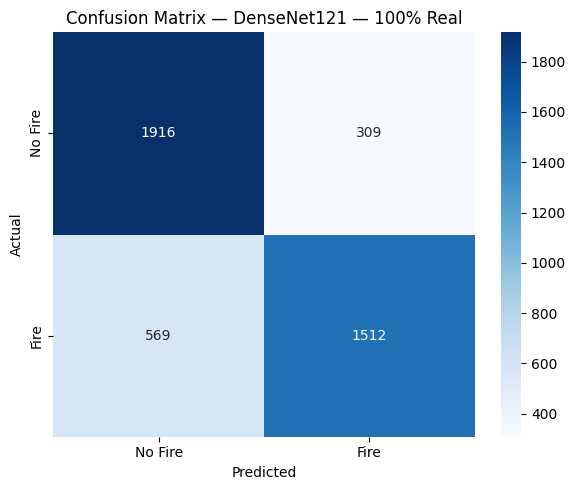

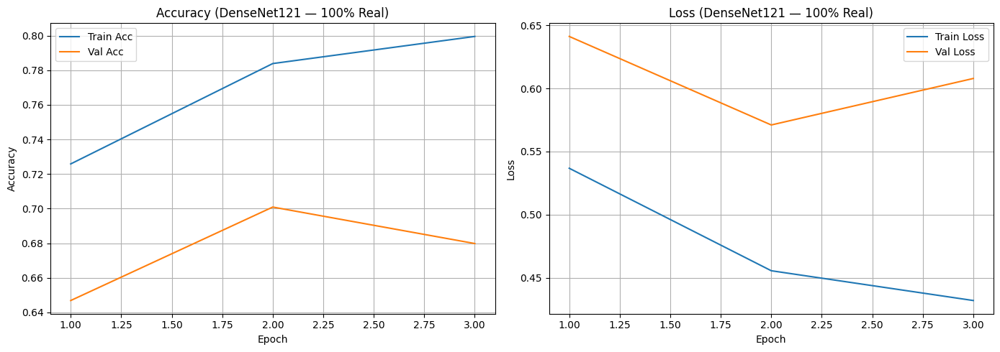

{'Split': 'DenseNet121 — 100% Real',
 'Accuracy': 0.796098467254993,
 'Precision (Fire)': 0.8303130148270181,
 'Recall (Fire)': 0.7265737626141279,
 'F1-Score (Fire)': 0.7749871860584315}

In [67]:
# Evaluate on REAL test set
metrics_real_dn = evaluate_on_real(
    model=model_real,
    real_test_batched=real_test_batched,
    split_name="DenseNet121 — 100% Real",
    plot_cm=True
)

# Plot training curves (from saved JSON)
plot_history_from_path(model_path_real, title_suffix="(DenseNet121 — 100% Real)")

metrics_real_dn

# 100% Synthethic 

In [68]:
# Exact-ratio mixer: trims to deliver the precise syn_ratio in the final dataset
def make_mixed_ds(real_unbatched, syn_unbatched, syn_ratio, batch_size=32):
    r_n = tf.data.experimental.cardinality(real_unbatched).numpy()
    s_n = tf.data.experimental.cardinality(syn_unbatched).numpy()
    # Find max k such that k*syn_ratio <= s_n and k*(1-syn_ratio) <= r_n
    k_syn  = s_n / max(syn_ratio, 1e-9)
    k_real = r_n / max(1.0 - syn_ratio, 1e-9)
    k = int(min(k_syn, k_real))
    take_syn  = int(round(k * syn_ratio))
    take_real = int(round(k * (1.0 - syn_ratio)))
    ds = syn_unbatched.take(take_syn).concatenate(real_unbatched.take(take_real))
    ds = ds.shuffle(10000)
    return ensure_batched(ds, batch_size)


In [69]:
# Train input
syn_train_batched = ensure_batched(synthetic_train_ds, BATCH_SIZE)
val_batched       = ensure_batched(VAL_DS, BATCH_SIZE)          # same validation you used for 100% real
real_test_batched = ensure_batched(real_test_ds, BATCH_SIZE)    # always evaluate on REAL

model_path_syn = "densenet121_synthetic_only.keras"
model_syn, _   = train_or_load(model_path_syn, syn_train_batched, val_batched)




 Training DenseNet121 from scratch...
Epoch 1/100
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 713ms/step - accuracy: 0.8490 - loss: 0.3424
Epoch 1: val_loss improved from inf to 0.23003, saving model to densenet121_synthetic_only.keras
88/88 ━━━━━━━━━━━━━━━━━━━━ 87s 937ms/step - accuracy: 0.8493 - loss: 0.3417 - val_accuracy: 0.9065 - val_loss: 0.2300 - learning_rate: 0.0010
Epoch 2/100
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 728ms/step - accuracy: 0.9199 - loss: 0.2150
Epoch 2: val_loss improved from 0.23003 to 0.19403, saving model to densenet121_synthetic_only.keras
88/88 ━━━━━━━━━━━━━━━━━━━━ 85s 946ms/step - accuracy: 0.9199 - loss: 0.2149 - val_accuracy: 0.9236 - val_loss: 0.1940 - learning_rate: 0.0010
Epoch 3/100
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 736ms/step - accuracy: 0.9312 - loss: 0.1916
Epoch 3: val_loss improved from 0.19403 to 0.17676, saving model to densenet121_synthetic_only.keras
88/88 ━━━━━━━━━━━━━━━━━━━━ 86s 958ms/step - accuracy: 0.9312 - loss: 0.1915 - val_accuracy: 0.9341 - val_loss: 0.1768 

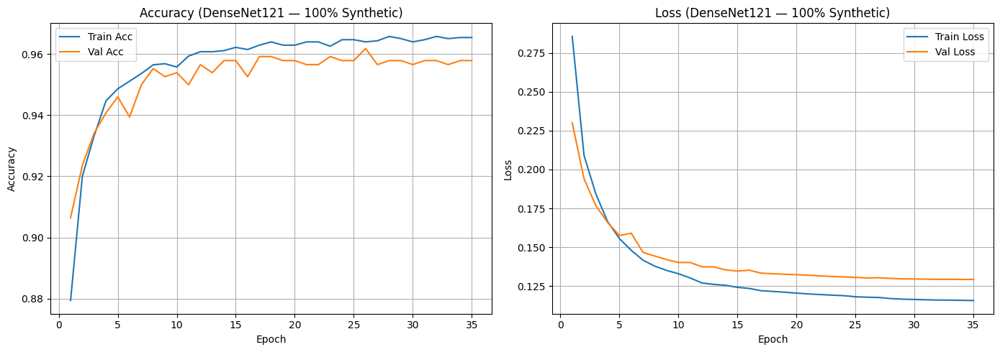


 DenseNet121 — 100% Synthetic — Classification Report
              precision    recall  f1-score   support

     No Fire       0.67      0.36      0.47      2225
        Fire       0.54      0.81      0.65      2081

    accuracy                           0.58      4306
   macro avg       0.61      0.59      0.56      4306
weighted avg       0.61      0.58      0.56      4306



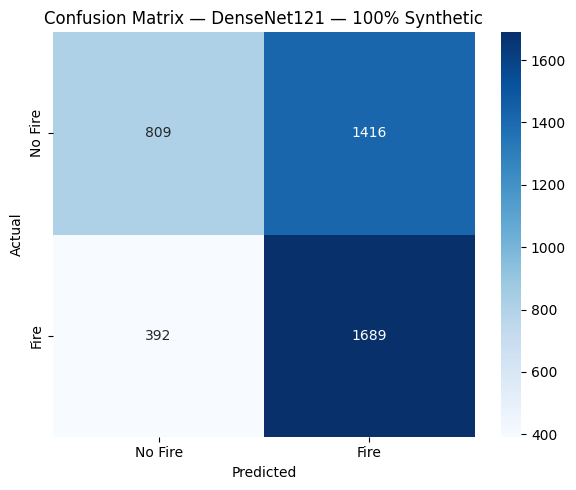

{'Split': 'DenseNet121 — 100% Synthetic',
 'Accuracy': 0.5801207617278217,
 'Precision (Fire)': 0.5439613526570048,
 'Recall (Fire)': 0.8116290245074483,
 'F1-Score (Fire)': 0.651369070574624}

In [70]:
plot_history_from_path(model_path_syn, "(DenseNet121 — 100% Synthetic)")
metrics_syn_dn = evaluate_on_real(model_syn, real_test_batched, "DenseNet121 — 100% Synthetic", plot_cm=True)

metrics_syn_dn

## 80% Synthetic / 20% Real

 Training DenseNet121 from scratch...
Epoch 1/100


2025-08-31 01:22:44.399984: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:452] ShuffleDatasetV3:6946: Filling up shuffle buffer (this may take a while): 2863 of 10000
2025-08-31 01:22:45.268739: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:482] Shuffle buffer filled.


110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 767ms/step - accuracy: 0.7400 - loss: 0.5200
Epoch 1: val_loss improved from inf to 0.25447, saving model to densenet121_mix_80_20.keras
110/110 ━━━━━━━━━━━━━━━━━━━━ 119s 957ms/step - accuracy: 0.7405 - loss: 0.5191 - val_accuracy: 0.9038 - val_loss: 0.2545 - learning_rate: 0.0010
Epoch 2/100


2025-08-31 01:24:40.434359: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:452] ShuffleDatasetV3:6946: Filling up shuffle buffer (this may take a while): 2803 of 10000
2025-08-31 01:24:41.374137: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:482] Shuffle buffer filled.


110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 764ms/step - accuracy: 0.8622 - loss: 0.3114
Epoch 2: val_loss improved from 0.25447 to 0.20891, saving model to densenet121_mix_80_20.keras
110/110 ━━━━━━━━━━━━━━━━━━━━ 115s 950ms/step - accuracy: 0.8622 - loss: 0.3114 - val_accuracy: 0.9236 - val_loss: 0.2089 - learning_rate: 0.0010
Epoch 3/100


...

110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 799ms/step - accuracy: 0.9137 - loss: 0.2096
Epoch 17: ReduceLROnPlateau reducing learning rate to 6.25000029685907e-05.

Epoch 17: val_loss did not improve from 0.14197
110/110 ━━━━━━━━━━━━━━━━━━━━ 120s 985ms/step - accuracy: 0.9136 - loss: 0.2097 - val_accuracy: 0.9486 - val_loss: 0.1423 - learning_rate: 1.2500e-04
Epoch 18/100


2025-08-31 01:56:13.620074: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:452] ShuffleDatasetV3:6946: Filling up shuffle buffer (this may take a while): 2803 of 10000
2025-08-31 01:56:14.549002: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:482] Shuffle buffer filled.


110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 795ms/step - accuracy: 0.9069 - loss: 0.2158
Epoch 18: ReduceLROnPlateau reducing learning rate to 3.125000148429535e-05.

Epoch 18: val_loss did not improve from 0.14197
110/110 ━━━━━━━━━━━━━━━━━━━━ 119s 983ms/step - accuracy: 0.9069 - loss: 0.2158 - val_accuracy: 0.9486 - val_loss: 0.1421 - learning_rate: 6.2500e-05
Epoch 19/100


2025-08-31 01:58:13.082358: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:452] ShuffleDatasetV3:6946: Filling up shuffle buffer (this may take a while): 2803 of 10000
2025-08-31 01:58:13.985823: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:482] Shuffle buffer filled.


110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 785ms/step - accuracy: 0.9085 - loss: 0.2279
Epoch 19: ReduceLROnPlateau reducing learning rate to 1.5625000742147677e-05.

Epoch 19: val_loss did not improve from 0.14197
110/110 ━━━━━━━━━━━━━━━━━━━━ 118s 970ms/step - accuracy: 0.9085 - loss: 0.2278 - val_accuracy: 0.9473 - val_loss: 0.1424 - learning_rate: 3.1250e-05
Epoch 19: early stopping
Restoring model weights from the end of the best epoch: 16.

 DenseNet121 — 80% Synthetic / 20% Real — Classification Report
              precision    recall  f1-score   support

     No Fire       0.74      0.74      0.74      2225
        Fire       0.72      0.72      0.72      2081

    accuracy                           0.73      4306
   macro avg       0.73      0.73      0.73      4306
weighted avg       0.73      0.73      0.73      4306



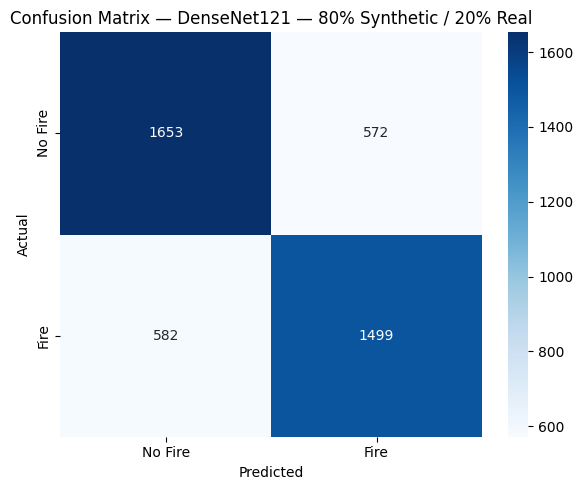

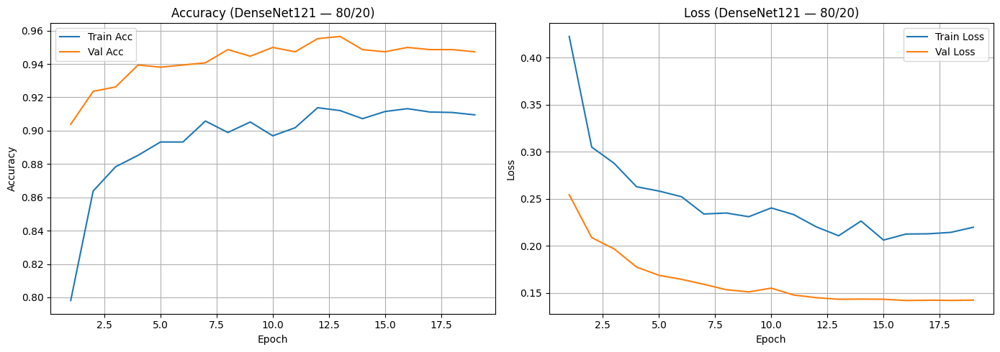

{'Split': 'DenseNet121 — 80% Synthetic / 20% Real',
 'Accuracy': 0.7320018578727358,
 'Precision (Fire)': 0.7238049251569291,
 'Recall (Fire)': 0.7203267659778952,
 'F1-Score (Fire)': 0.7220616570327553}

In [71]:
mixed_80_20 = make_mixed_ds(real_unbatched=real_train_ds, syn_unbatched=synthetic_train_ds, syn_ratio=0.8, batch_size=BATCH_SIZE)
val_batched       = ensure_batched(VAL_DS, BATCH_SIZE)
real_test_batched = ensure_batched(real_test_ds, BATCH_SIZE)

model_path_80_20 = "densenet121_mix_80_20.keras"
model_80_20, _   = train_or_load(model_path_80_20, mixed_80_20, val_batched)

metrics_80_20_dn = evaluate_on_real(model_80_20, real_test_batched, "DenseNet121 — 80% Synthetic / 20% Real", plot_cm=True)
plot_history_from_path(model_path_80_20, "(DenseNet121 — 80/20)")

metrics_80_20_dn


## 50% / 50%

 Training DenseNet121 from scratch...
Epoch 1/100


2025-08-31 02:02:11.334430: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:452] ShuffleDatasetV3:8714: Filling up shuffle buffer (this may take a while): 2803 of 10000
2025-08-31 02:02:14.279854: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:482] Shuffle buffer filled.


176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 838ms/step - accuracy: 0.6925 - loss: 0.5611
Epoch 1: val_loss improved from inf to 0.24075, saving model to densenet121_mix_50_50.keras
176/176 ━━━━━━━━━━━━━━━━━━━━ 186s 963ms/step - accuracy: 0.6928 - loss: 0.5607 - val_accuracy: 0.9170 - val_loss: 0.2408 - learning_rate: 0.0010
Epoch 2/100


2025-08-31 02:05:14.188906: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:452] ShuffleDatasetV3:8714: Filling up shuffle buffer (this may take a while): 2803 of 10000
2025-08-31 02:05:16.939805: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:482] Shuffle buffer filled.


176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 806ms/step - accuracy: 0.8079 - loss: 0.4042
Epoch 2: val_loss improved from 0.24075 to 0.21317, saving model to densenet121_mix_50_50.keras
176/176 ━━━━━━━━━━━━━━━━━━━━ 175s 922ms/step - accuracy: 0.8080 - loss: 0.4041 - val_accuracy: 0.9236 - val_loss: 0.2132 - learning_rate: 0.0010
Epoch 3/100


...

176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 799ms/step - accuracy: 0.8725 - loss: 0.2994
Epoch 18: ReduceLROnPlateau reducing learning rate to 6.25000029685907e-05.

Epoch 18: val_loss did not improve from 0.15609
176/176 ━━━━━━━━━━━━━━━━━━━━ 174s 915ms/step - accuracy: 0.8725 - loss: 0.2994 - val_accuracy: 0.9341 - val_loss: 0.1608 - learning_rate: 1.2500e-04
Epoch 19/100


2025-08-31 02:54:36.015014: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:452] ShuffleDatasetV3:8714: Filling up shuffle buffer (this may take a while): 2803 of 10000
2025-08-31 02:54:38.666976: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:482] Shuffle buffer filled.


176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 800ms/step - accuracy: 0.8673 - loss: 0.3045
Epoch 19: ReduceLROnPlateau reducing learning rate to 3.125000148429535e-05.

Epoch 19: val_loss did not improve from 0.15609
176/176 ━━━━━━━━━━━━━━━━━━━━ 175s 918ms/step - accuracy: 0.8673 - loss: 0.3045 - val_accuracy: 0.9407 - val_loss: 0.1564 - learning_rate: 6.2500e-05
Epoch 20/100


2025-08-31 02:57:30.693022: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:452] ShuffleDatasetV3:8714: Filling up shuffle buffer (this may take a while): 2803 of 10000
2025-08-31 02:57:33.357239: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:482] Shuffle buffer filled.


176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 802ms/step - accuracy: 0.8668 - loss: 0.2931
Epoch 20: ReduceLROnPlateau reducing learning rate to 1.5625000742147677e-05.

⛔ Stopping early: overfitting detected (bad_epochs=2, gap=-0.134).

Epoch 20: val_loss did not improve from 0.15609
176/176 ━━━━━━━━━━━━━━━━━━━━ 175s 919ms/step - accuracy: 0.8669 - loss: 0.2931 - val_accuracy: 0.9394 - val_loss: 0.1563 - learning_rate: 3.1250e-05
Epoch 20: early stopping
Restoring model weights from the end of the best epoch: 17.

 DenseNet121 — 50% Synthetic / 50% Real — Classification Report
              precision    recall  f1-score   support

     No Fire       0.78      0.83      0.80      2225
        Fire       0.81      0.74      0.77      2081

    accuracy                           0.79      4306
   macro avg       0.79      0.79      0.79      4306
weighted avg       0.79      0.79      0.79      4306



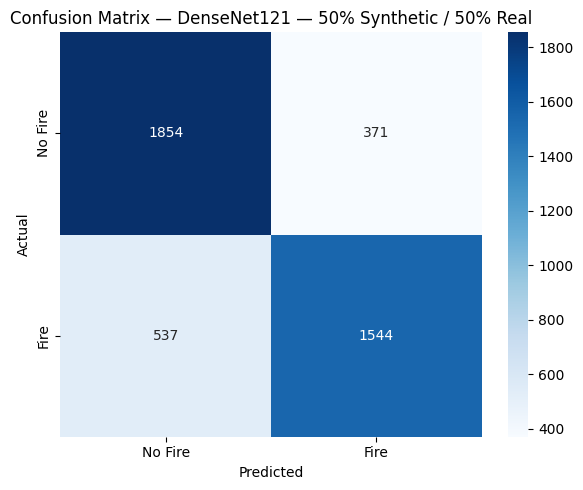

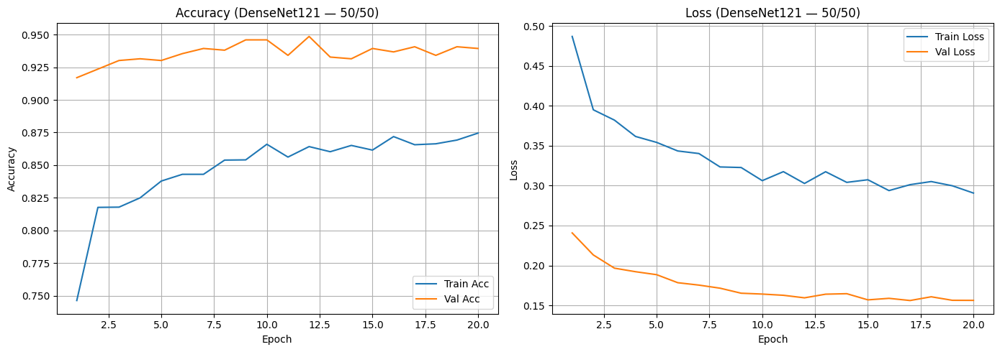

{'Split': 'DenseNet121 — 50% Synthetic / 50% Real',
 'Accuracy': 0.789131444496052,
 'Precision (Fire)': 0.806266318537859,
 'Recall (Fire)': 0.7419509851033157,
 'F1-Score (Fire)': 0.7727727727727728}

In [72]:
mixed_50_50 = make_mixed_ds(real_unbatched=real_train_ds, syn_unbatched=synthetic_train_ds, syn_ratio=0.5, batch_size=BATCH_SIZE)
val_batched       = ensure_batched(VAL_DS, BATCH_SIZE)
real_test_batched = ensure_batched(real_test_ds, BATCH_SIZE)

model_path_50_50 = "densenet121_mix_50_50.keras"
model_50_50, _   = train_or_load(model_path_50_50, mixed_50_50, val_batched)

metrics_50_50_dn = evaluate_on_real(model_50_50, real_test_batched, "DenseNet121 — 50% Synthetic / 50% Real", plot_cm=True)
plot_history_from_path(model_path_50_50, "(DenseNet121 — 50/50)")

metrics_50_50_dn


 ## 20% Synthetic / 80% Real

 Training DenseNet121 from scratch...
Epoch 1/100


2025-08-31 03:02:24.579167: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:452] ShuffleDatasetV3:10482: Filling up shuffle buffer (this may take a while): 2803 of 10000
2025-08-31 03:02:30.806608: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:482] Shuffle buffer filled.


438/438 ━━━━━━━━━━━━━━━━━━━━ 0s 815ms/step - accuracy: 0.6966 - loss: 0.5589
Epoch 1: val_loss improved from inf to 0.24289, saving model to densenet121_mix_20_80.keras
438/438 ━━━━━━━━━━━━━━━━━━━━ 399s 866ms/step - accuracy: 0.6967 - loss: 0.5588 - val_accuracy: 0.9196 - val_loss: 0.2429 - learning_rate: 0.0010
Epoch 2/100


2025-08-31 03:09:01.296343: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:452] ShuffleDatasetV3:10482: Filling up shuffle buffer (this may take a while): 2803 of 10000
2025-08-31 03:09:07.538242: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:482] Shuffle buffer filled.


438/438 ━━━━━━━━━━━━━━━━━━━━ 0s 809ms/step - accuracy: 0.7960 - loss: 0.4324
Epoch 2: val_loss improved from 0.24289 to 0.22060, saving model to densenet121_mix_20_80.keras
438/438 ━━━━━━━━━━━━━━━━━━━━ 392s 856ms/step - accuracy: 0.7960 - loss: 0.4324 - val_accuracy: 0.9223 - val_loss: 0.2206 - learning_rate: 0.0010
Epoch 3/100


...

2025-08-31 03:41:29.909544: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:452] ShuffleDatasetV3:10482: Filling up shuffle buffer (this may take a while): 2803 of 10000
2025-08-31 03:41:36.170491: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:482] Shuffle buffer filled.


438/438 ━━━━━━━━━━━━━━━━━━━━ 0s 802ms/step - accuracy: 0.8406 - loss: 0.3642
Epoch 7: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.

Epoch 7: val_loss did not improve from 0.20395
438/438 ━━━━━━━━━━━━━━━━━━━━ 388s 848ms/step - accuracy: 0.8406 - loss: 0.3643 - val_accuracy: 0.9262 - val_loss: 0.2047 - learning_rate: 2.5000e-04
Epoch 8/100


2025-08-31 03:47:58.299831: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:452] ShuffleDatasetV3:10482: Filling up shuffle buffer (this may take a while): 2803 of 10000
2025-08-31 03:48:04.371115: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:482] Shuffle buffer filled.


438/438 ━━━━━━━━━━━━━━━━━━━━ 0s 798ms/step - accuracy: 0.8399 - loss: 0.3718
Epoch 8: ReduceLROnPlateau reducing learning rate to 6.25000029685907e-05.

Epoch 8: val_loss did not improve from 0.20395
438/438 ━━━━━━━━━━━━━━━━━━━━ 386s 844ms/step - accuracy: 0.8399 - loss: 0.3718 - val_accuracy: 0.9209 - val_loss: 0.2127 - learning_rate: 1.2500e-04
Epoch 8: early stopping
Restoring model weights from the end of the best epoch: 5.

 DenseNet121 — 20% Synthetic / 80% Real — Classification Report
              precision    recall  f1-score   support

     No Fire       0.82      0.79      0.80      2225
        Fire       0.78      0.82      0.80      2081

    accuracy                           0.80      4306
   macro avg       0.80      0.80      0.80      4306
weighted avg       0.80      0.80      0.80      4306



2025-08-31 03:56:06.570311: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


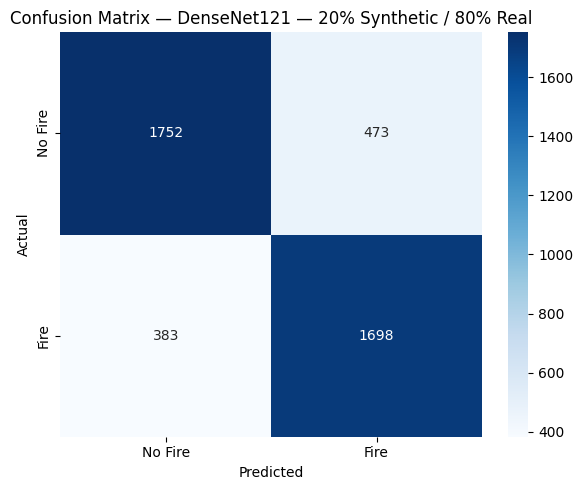

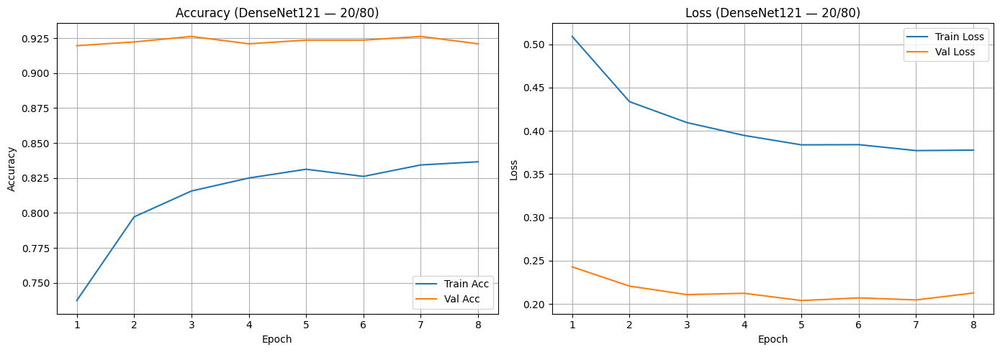

{'Split': 'DenseNet121 — 20% Synthetic / 80% Real',
 'Accuracy': 0.8012076172782164,
 'Precision (Fire)': 0.7821280515891295,
 'Recall (Fire)': 0.8159538683325325,
 'F1-Score (Fire)': 0.7986829727187206}

In [73]:
mixed_20_80 = make_mixed_ds(real_unbatched=real_train_ds, syn_unbatched=synthetic_train_ds, syn_ratio=0.2, batch_size=BATCH_SIZE)
val_batched       = ensure_batched(VAL_DS, BATCH_SIZE)
real_test_batched = ensure_batched(real_test_ds, BATCH_SIZE)

model_path_20_80 = "densenet121_mix_20_80.keras"
model_20_80, _   = train_or_load(model_path_20_80, mixed_20_80, val_batched)

metrics_20_80_dn = evaluate_on_real(model_20_80, real_test_batched, "DenseNet121 — 20% Synthetic / 80% Real", plot_cm=True)
plot_history_from_path(model_path_20_80, "(DenseNet121 — 20/80)")

metrics_20_80_dn


In [81]:
import pandas as pd

rows_dn = [metrics_real_dn, metrics_syn_dn, metrics_80_20_dn, metrics_50_50_dn, metrics_20_80_dn]
comparison_dn = pd.DataFrame([r for r in rows_dn if r is not None])


display(comparison_dn)


,Split,Accuracy,Precision (Fire),Recall (Fire),F1-Score (Fire)
0,DenseNet121 — 100% Real,0.796098,0.830313,0.726574,0.774987
1,DenseNet121 — 100% Synthetic,0.580121,0.543961,0.811629,0.651369
2,DenseNet121 — 80% Synthetic / 20% Real,0.732002,0.723805,0.720327,0.722062
3,DenseNet121 — 50% Synthetic / 50% Real,0.789131,0.806266,0.741951,0.772773
4,DenseNet121 — 20% Synthetic / 80% Real,0.801208,0.782128,0.815954,0.798683


In [30]:
comparison_dn = pd.read_csv("dense_metrics.csv")

In [31]:
comparison_dn

,Split,Accuracy,Precision (Fire),Recall (Fire),F1-Score (Fire)
0,DenseNet121 — 100% Real,0.796098,0.830313,0.726574,0.774987
1,DenseNet121 — 100% Synthetic,0.580121,0.543961,0.811629,0.651369
2,DenseNet121 — 80% Synthetic / 20% Real,0.732002,0.723805,0.720327,0.722062
3,DenseNet121 — 50% Synthetic / 50% Real,0.789131,0.806266,0.741951,0.772773
4,DenseNet121 — 20% Synthetic / 80% Real,0.801208,0.782128,0.815954,0.798683


In [32]:

order = [
    "DenseNet121 — 100% Real",
    "DenseNet121 — 20% Synthetic / 80% Real",
    "DenseNet121 — 50% Synthetic / 50% Real",
    "DenseNet121 — 80% Synthetic / 20% Real",
    "DenseNet121 — 100% Synthetic"
]


# Reorder using categorical
comparison_dn["Split"] = pd.Categorical(comparison_dn["Split"], categories=order, ordered=True)
comparison_dn = comparison_dn.sort_values("Split").reset_index(drop=True)


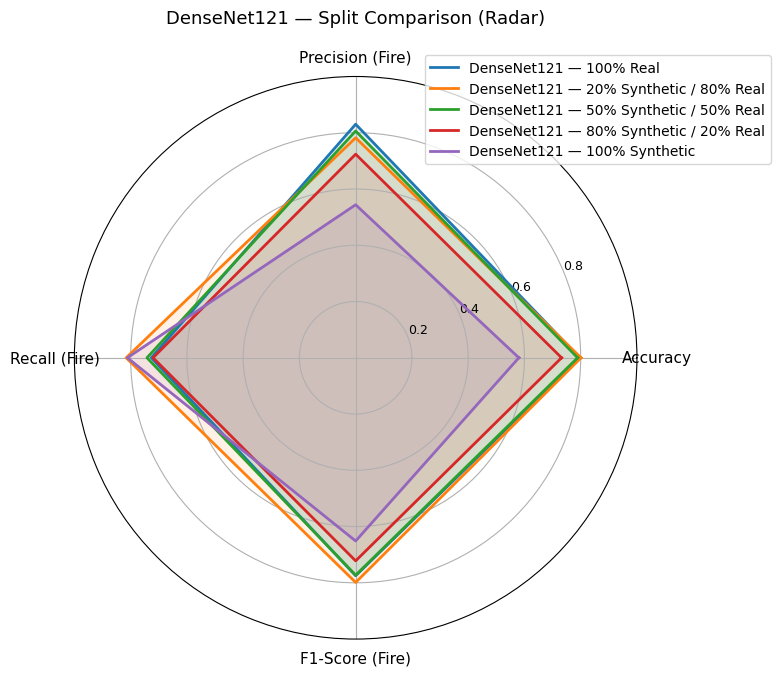

In [33]:

def plot_radar_for_splits(df, title="DenseNet121 — Split Comparison (Radar)"):
    # Ensure required columns exist
    metrics = ["Accuracy", "Precision (Fire)", "Recall (Fire)", "F1-Score (Fire)"]
    df = df.dropna(subset=metrics)  # drop incomplete rows if any
    
    # Data matrix (rows = splits, cols = metrics)
    data = df[metrics].values.astype(float)
    labels = metrics
    splits = df["Split"].tolist()

    # Radar setup
    num_vars = len(labels)
    angles = np.linspace(0, 2*np.pi, num_vars, endpoint=False).tolist()
    angles += angles[:1]  # close the loop

    # Normalize axis from 0 to 1 (most of your metrics are already in [0,1])
    # If you want auto-scaling across rows, keep as-is.
    fig = plt.figure(figsize=(8, 8))
    ax = plt.subplot(111, polar=True)

    # Draw one polygon per split
    for i, split in enumerate(splits):
        values = data[i].tolist()
        values += values[:1]  # close the loop
        ax.plot(angles, values, linewidth=2, label=split)
        ax.fill(angles, values, alpha=0.1)

    # Category labels
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(labels, fontsize=11)
    # Radial ticks (0.0 to 1.0)
    ax.set_yticks([0.2, 0.4, 0.6, 0.8])
    ax.set_yticklabels(["0.2","0.4","0.6","0.8"], fontsize=9)
    ax.set_ylim(0, 1.0)

    plt.title(title, y=1.08, fontsize=13)
    plt.legend(loc="upper right", bbox_to_anchor=(1.25, 1.05))
    plt.tight_layout()
    plt.show()

# ---- call it on your dataframe ----
plot_radar_for_splits(comparison_dn)

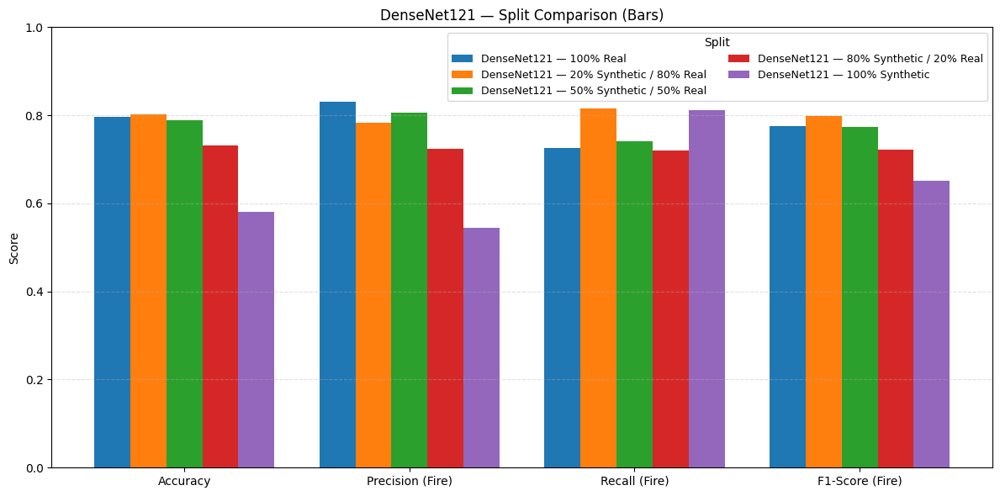

In [34]:

def plot_grouped_bars(df, title="DenseNet121 — Split Comparison (Bars)"):
    metrics = ["Accuracy", "Precision (Fire)", "Recall (Fire)", "F1-Score (Fire)"]
    df = df.dropna(subset=metrics)
    splits = df["Split"].tolist()
    M = len(metrics)
    S = len(splits)

    # Values S x M
    vals = df[metrics].values.astype(float)  # rows = splits, cols = metrics

    x = np.arange(M)  # metric positions
    width = 0.8 / max(S, 1)  # bar width so all splits fit within 0.8 span

    plt.figure(figsize=(12, 6))
    for i, split in enumerate(splits):
        plt.bar(x + i*width, vals[i], width=width, label=split)

    plt.xticks(x + width*(S-1)/2, metrics, rotation=0)
    plt.ylim(0, 1.0)
    plt.ylabel("Score")
    plt.title(title)
    plt.grid(axis="y", linestyle="--", alpha=0.4)
    plt.legend(title="Split", ncol=2, fontsize=9)
    plt.tight_layout()
    plt.show()

# ---- call it ----
plot_grouped_bars(comparison_dn)

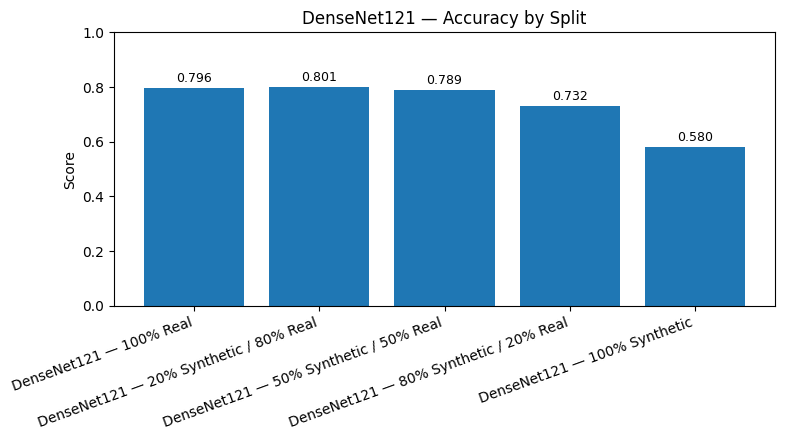

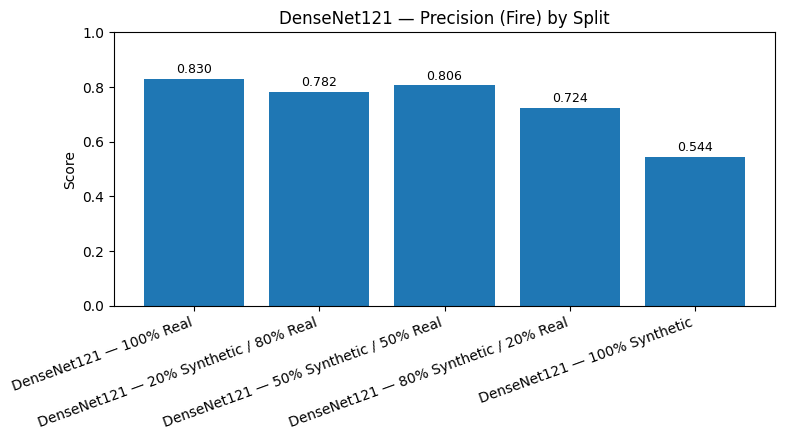

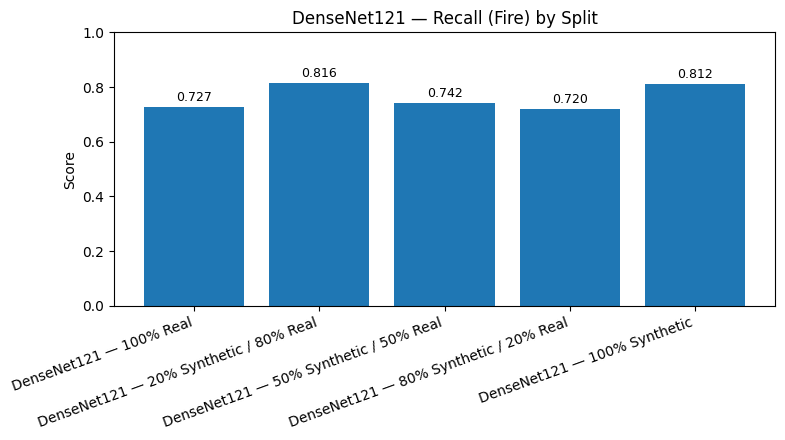

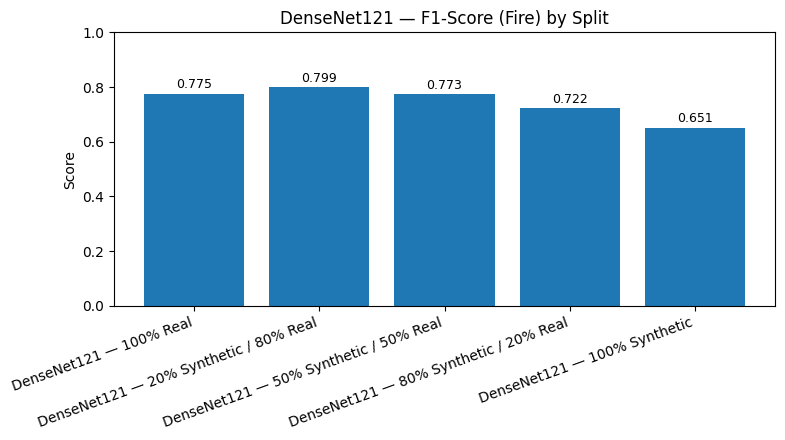

In [35]:
METRICS = ["Accuracy", "Precision (Fire)", "Recall (Fire)", "F1-Score (Fire)"]

def plot_metric_for_df(df, metric_col, title=None, ylabel="Score", ylim=(0, 1.0)):
    # Ensure required columns exist
    if "Split" not in df.columns or metric_col not in df.columns:
        raise ValueError(f"DataFrame must have columns ['Split', '{metric_col}'].")

    # Use DF order for splits
    splits = df["Split"].tolist()
    values = df[metric_col].astype(float).values
    x = np.arange(len(values))

    plt.figure(figsize=(8, 4.5))
    bars = plt.bar(x, values)
    plt.xticks(x, splits, rotation=20, ha="right")
    plt.ylim(*ylim)
    plt.ylabel(ylabel)
    plt.title(title or f"{metric_col} by Split")

    # Value labels
    for rect, v in zip(bars, values):
        plt.text(rect.get_x() + rect.get_width()/2, rect.get_height() + 0.01,
                 f"{v:.3f}", ha="center", va="bottom", fontsize=9)

    plt.tight_layout()
    plt.show()

def plot_all_metrics_for_df(df, title_prefix=""):
    for m in METRICS:
        plot_metric_for_df(df, m, title=f"{title_prefix}{m} by Split")

# For DenseNet121 table
plot_all_metrics_for_df(comparison_dn, title_prefix="DenseNet121 — ")


In [36]:
# comparison_df = pd.read_csv("light_metrics.csv")

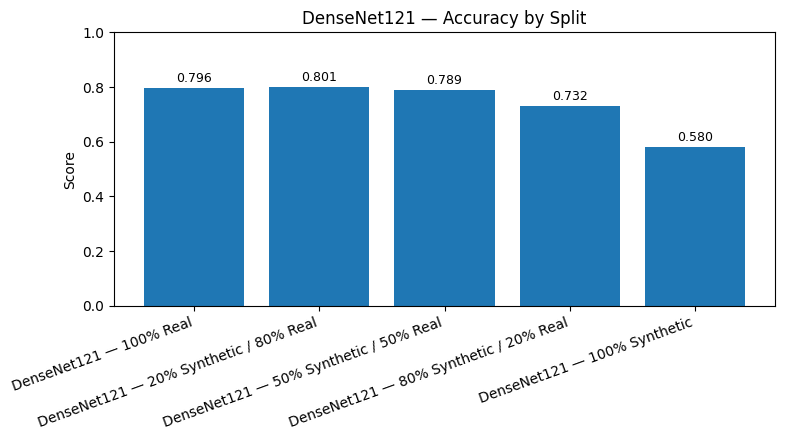

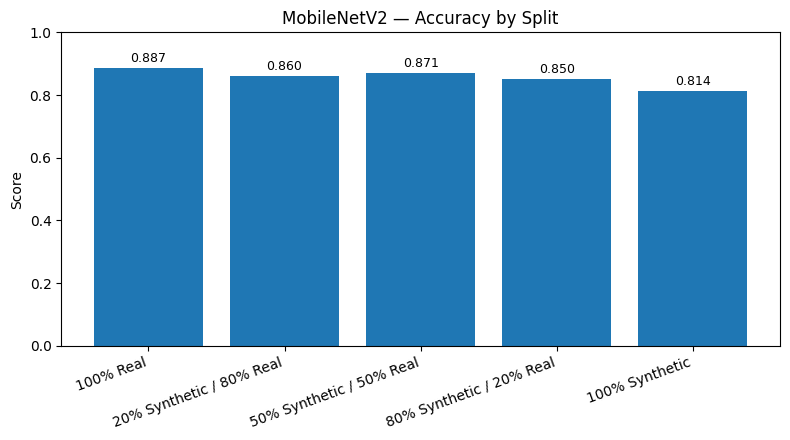

In [37]:
def plot_metric(df, metric_col, title, ylabel="Score", ylim=(0, 1.0)):
    if "Split" not in df.columns or metric_col not in df.columns:
        raise ValueError(f"DataFrame must have columns ['Split', '{metric_col}'].")

    splits = df["Split"].tolist()
    values = df[metric_col].astype(float).values
    x = np.arange(len(values))

    plt.figure(figsize=(8, 4.5))
    bars = plt.bar(x, values)
    plt.xticks(x, splits, rotation=20, ha="right")
    plt.ylim(*ylim)
    plt.ylabel(ylabel)
    plt.title(title)

    for rect, v in zip(bars, values):
        plt.text(rect.get_x() + rect.get_width()/2, rect.get_height() + 0.01,
                 f"{v:.3f}", ha="center", va="bottom", fontsize=9)

    plt.tight_layout()
    plt.show()

# Example reuse on any df you already have:
plot_metric(comparison_dn, "Accuracy", "DenseNet121 — Accuracy by Split")
plot_metric(comparison_df, "Accuracy", "MobileNetV2 — Accuracy by Split")


In [38]:
# comparison_dn.to_csv("dense_metrics.csv",index=False)

In [96]:
comparison_df

,Split,Accuracy,Precision (Fire),Recall (Fire),F1-Score (Fire)
0,100% Real,0.886670,0.924193,0.858322,0.890041
1,100% Synthetic,0.813980,0.813283,0.846154,0.829393
2,80% Synthetic / 20% Real,0.850209,0.831793,0.864969,0.848057
3,50% Synthetic/50% Real,0.870646,0.860454,0.874099,0.867223
4,20% Synthetic/80% Real,0.859963,0.874367,0.829409,0.851295


In [39]:
import re
CANONICAL = {
    "100% REAL": "100% Real",
    "100% SYNTHETIC": "100% Synthetic",
    "80% SYNTHETIC / 20% REAL": "80% Synthetic / 20% Real",
    "50% SYNTHETIC / 50% REAL": "50% Synthetic / 50% Real",
    "20% SYNTHETIC / 80% REAL": "20% Synthetic / 80% Real",
}

def normalize_split(s: str) -> str:
    if not isinstance(s, str):
        return s
    x = s

    # 1) Drop any model prefix like "DenseNet121 — " or "MobileNetV2 - "
    x = re.split(r"[—–-]\s*", x, maxsplit=1)[-1]  # split on em/en/hyphen dash if present

    # 2) Standardize dashes and ensure spaces around '/'
    x = x.replace("—", "-").replace("–", "-")
    x = x.replace("/", " / ")

    # 3) Collapse whitespace
    x = re.sub(r"\s+", " ", x).strip()

    # 4) Uppercase for matching, then map to canonical case
    key = x.upper()
    # Common typos (no spaces around slash)
    key = key.replace("SYNTHETIC/ ", "SYNTHETIC / ").replace("SYNTHETIC/","SYNTHETIC / ")
    key = key.replace("/20", " / 20").replace("/50", " / 50").replace("/80", " / 80")

    # 5) Final cleanup of possible double spaces
    key = re.sub(r"\s+", " ", key).strip()

    return CANONICAL.get(key, x)  # fall back to cleaned x if not matched

def normalize_comparison_df(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    if "Split" not in df.columns:
        raise ValueError("DataFrame must contain a 'Split' column.")
    df["Split"] = df["Split"].apply(normalize_split)
    # Ensure metric columns are numeric
    for col in ["Accuracy", "Precision (Fire)", "Recall (Fire)", "F1-Score (Fire)"]:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")
    return df

# --- Apply to your two tables ---
comparison_dn = normalize_comparison_df(comparison_dn)
comparison_df = normalize_comparison_df(comparison_df)

print("DN splits:", comparison_dn["Split"].tolist())
print("MV2 splits:", comparison_df["Split"].tolist())

DN splits: ['100% Real', '20% Synthetic / 80% Real', '50% Synthetic / 50% Real', '80% Synthetic / 20% Real', '100% Synthetic']
MV2 splits: ['100% Real', '20% Synthetic / 80% Real', '50% Synthetic / 50% Real', '80% Synthetic / 20% Real', '100% Synthetic']


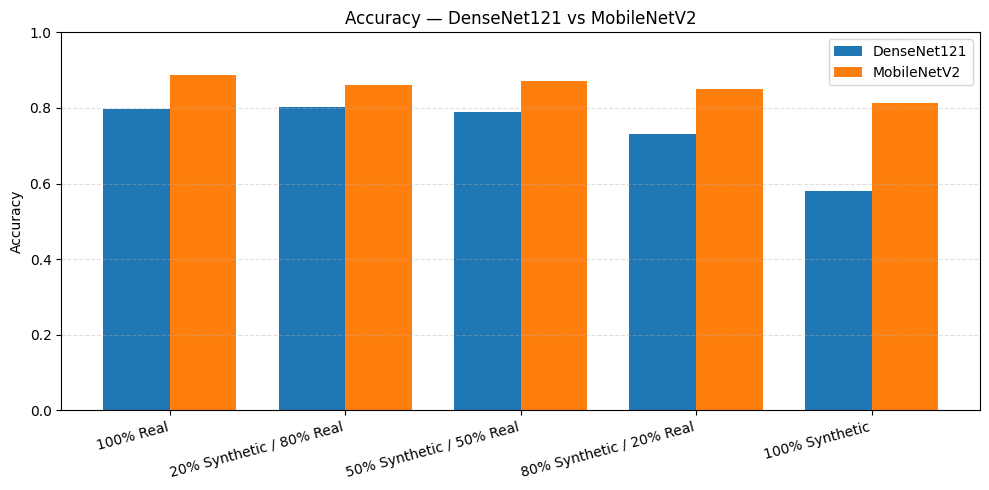

In [40]:
# quick check: single-metric grouped bars after normalisation
def quick_grouped(df1, df2, metric="Accuracy", labels=("DenseNet121","MobileNetV2")):
    # align
    common = [s for s in df1["Split"] if s in set(df2["Split"])]
    a = df1[df1["Split"].isin(common)].copy()
    b = df2[df2["Split"].isin(common)].copy()
    a["__o__"] = a["Split"].apply(common.index)
    b["__o__"] = b["Split"].apply(common.index)
    a = a.sort_values("__o__"); b = b.sort_values("__o__")
    a = a.drop(columns="__o__"); b = b.drop(columns="__o__")

    import numpy as np, matplotlib.pyplot as plt
    x = np.arange(len(common)); width = 0.38
    plt.figure(figsize=(10,5))
    plt.bar(x - width/2, a[metric], width=width, label=labels[0])
    plt.bar(x + width/2, b[metric], width=width, label=labels[1])
    plt.xticks(x, common, rotation=15, ha="right")
    plt.ylim(0,1.0); plt.ylabel(metric); plt.title(f"{metric} — {labels[0]} vs {labels[1]}")
    plt.grid(axis="y", linestyle="--", alpha=0.4); plt.legend(); plt.tight_layout(); plt.show()

quick_grouped(comparison_dn, comparison_df, metric="Accuracy",
              labels=("DenseNet121","MobileNetV2"))

In [41]:
def debug_df(df, name="df"):
    print(f"\n==== {name} shape:", df.shape)
    print(df.head(10))
    print("\ncolumns:", list(df.columns))
    print("\ndtypes:")
    print(df.dtypes)
    # Basic checks
    required = {"Split", "Accuracy", "Precision (Fire)", "Recall (Fire)", "F1-Score (Fire)"}
    missing = required - set(df.columns)
    if missing:
        print(f"⚠️ Missing columns in {name}: {missing}")
    # Coerce numerics
    for col in ["Accuracy", "Precision (Fire)", "Recall (Fire)", "F1-Score (Fire)"]:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")
    if df[["Accuracy","Precision (Fire)","Recall (Fire)","F1-Score (Fire)"]].isna().all().all():
        print(f"⚠️ All metric values are NaN in {name} after coercion.")
    return df

# Example:
comparison_dn = debug_df(comparison_dn, "comparison_dn")
comparison_df = debug_df(comparison_df, "comparison_df")


==== comparison_dn shape: (5, 5)
                      Split  Accuracy  Precision (Fire)  Recall (Fire)  \
0                 100% Real  0.796098          0.830313       0.726574   
1  20% Synthetic / 80% Real  0.801208          0.782128       0.815954   
2  50% Synthetic / 50% Real  0.789131          0.806266       0.741951   
3  80% Synthetic / 20% Real  0.732002          0.723805       0.720327   
4            100% Synthetic  0.580121          0.543961       0.811629   

   F1-Score (Fire)  
0         0.774987  
1         0.798683  
2         0.772773  
3         0.722062  
4         0.651369  

columns: ['Split', 'Accuracy', 'Precision (Fire)', 'Recall (Fire)', 'F1-Score (Fire)']

dtypes:
Split               category
Accuracy             float64
Precision (Fire)     float64
Recall (Fire)        float64
F1-Score (Fire)      float64
dtype: object

==== comparison_df shape: (5, 5)
                      Split  Accuracy  Precision (Fire)  Recall (Fire)  \
0                 100% Real  0.

In [42]:

def align_on_splits(df1, df2):
    """Align two DFs by common Splits, preserving df1's split order."""
    common = [s for s in df1["Split"].tolist() if s in set(df2["Split"].tolist())]
    a = df1[df1["Split"].isin(common)].copy()
    b = df2[df2["Split"].isin(common)].copy()
    a["__ord__"] = a["Split"].apply(lambda s: common.index(s))
    b["__ord__"] = b["Split"].apply(lambda s: common.index(s))
    a = a.sort_values("__ord__").drop(columns="__ord__")
    b = b.sort_values("__ord__").drop(columns="__ord__")
    return a, b, common


==== DenseNet121 DF shape: (5, 5)
                      Split  Accuracy  Precision (Fire)  Recall (Fire)  \
0                 100% Real  0.796098          0.830313       0.726574   
1  20% Synthetic / 80% Real  0.801208          0.782128       0.815954   
2  50% Synthetic / 50% Real  0.789131          0.806266       0.741951   
3  80% Synthetic / 20% Real  0.732002          0.723805       0.720327   
4            100% Synthetic  0.580121          0.543961       0.811629   

   F1-Score (Fire)  
0         0.774987  
1         0.798683  
2         0.772773  
3         0.722062  
4         0.651369  

columns: ['Split', 'Accuracy', 'Precision (Fire)', 'Recall (Fire)', 'F1-Score (Fire)']

dtypes:
Split               category
Accuracy             float64
Precision (Fire)     float64
Recall (Fire)        float64
F1-Score (Fire)      float64
dtype: object

==== MobileNetV2 DF shape: (5, 5)
                      Split  Accuracy  Precision (Fire)  Recall (Fire)  \
0                 100% Real  

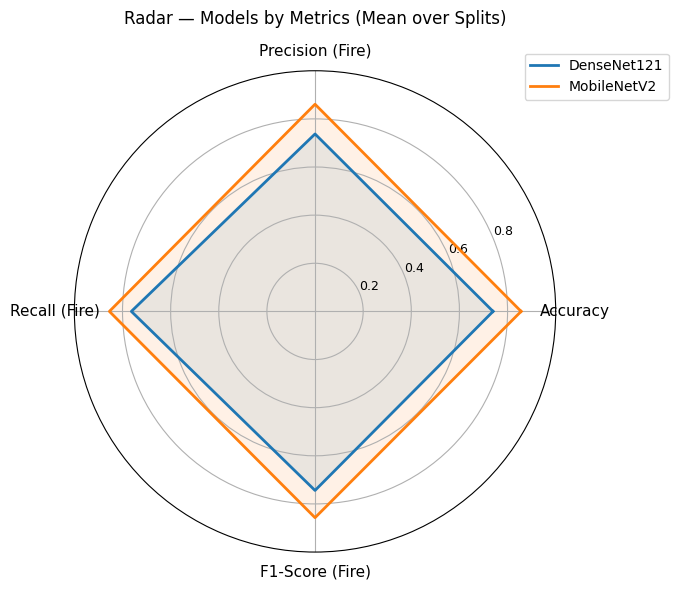

In [43]:
def plot_radar_mean_over_splits(df_dn, df_mv2, model_names=("DenseNet121","MobileNetV2"),
                                title="Radar — Models by Metrics (Mean over Splits)"):
    df_dn = debug_df(df_dn.copy(), "DenseNet121 DF")
    df_mv2 = debug_df(df_mv2.copy(), "MobileNetV2 DF")

    a, b, common = align_on_splits(df_dn, df_mv2)
    if a is None:
        return
    mean_dn = a[METRICS].apply(pd.to_numeric, errors="coerce").mean().fillna(0).values.tolist()
    mean_mv = b[METRICS].apply(pd.to_numeric, errors="coerce").mean().fillna(0).values.tolist()

    num_vars = len(METRICS)
    angles = np.linspace(0, 2*np.pi, num_vars, endpoint=False).tolist()
    angles += angles[:1]

    v_dn = mean_dn + mean_dn[:1]
    v_mv = mean_mv + mean_mv[:1]

    fig = plt.figure(figsize=(7,7))
    ax = plt.subplot(111, polar=True)
    ax.plot(angles, v_dn, linewidth=2, label=model_names[0])
    ax.fill(angles, v_dn, alpha=0.1)
    ax.plot(angles, v_mv, linewidth=2, label=model_names[1])
    ax.fill(angles, v_mv, alpha=0.1)

    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(METRICS, fontsize=11)
    ax.set_yticks([0.2,0.4,0.6,0.8])
    ax.set_yticklabels(["0.2","0.4","0.6","0.8"], fontsize=9)
    ax.set_ylim(0, 1.0)

    plt.title(title, y=1.08)
    plt.legend(loc="upper right", bbox_to_anchor=(1.25, 1.05))
    plt.tight_layout()
    plt.show()

# Example:
plot_radar_mean_over_splits(comparison_dn, comparison_df)